# SPECTRALIS VOL Analyzer

**Source:** [EyePy sample data v1.0.0](https://github.com/MedVisBonn/eyepydata/releases/tag/v1.0.0) (`healthy_OS.vol`, about 517 MiB). The example is for research/demo use, **not clinical diagnosis**.


## 1 — Install dependencies

EyePy reads Heidelberg HEYEX `.vol`; the other libraries handle image analysis, plotting, and report generation.

In [1]:
%pip -q install "eyepy>=0.21" scipy scikit-image imageio matplotlib numpy pandas

## 2 — Download the public `.vol` file

The sample is approximately **517 MiB**. This cell streams it into `/content/vol_samples/healthy_OS.vol`, displays progress, and checks the downloaded byte count. If the file is already complete, it will be reused.

In [2]:
from pathlib import Path
from urllib.request import Request, urlopen
from tqdm.auto import tqdm

DATA_DIR = Path("/content/vol_samples")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = DATA_DIR / "healthy_OS.vol"
URL = "https://github.com/MedVisBonn/eyepydata/releases/download/v1.0.0/healthy_OS.vol"
EXPECTED_BYTES = 541_657_220  # GitHub release asset size

if DATA_FILE.is_file() and DATA_FILE.stat().st_size == EXPECTED_BYTES:
    print("Already downloaded:", DATA_FILE)
else:
    # A partial/stale file should never be mistaken for a valid .vol.
    if DATA_FILE.exists():
        DATA_FILE.unlink()
    req = Request(URL, headers={"User-Agent": "Google-Colab-Spectralis-demo"})
    with urlopen(req, timeout=60) as response, DATA_FILE.open("wb") as dst:
        total = response.headers.get("Content-Length")
        total = int(total) if total else EXPECTED_BYTES
        with tqdm(total=total, unit="B", unit_scale=True, desc="Downloading healthy_OS.vol") as pbar:
            while True:
                block = response.read(8 * 1024 * 1024)
                if not block:
                    break
                dst.write(block)
                pbar.update(len(block))

size = DATA_FILE.stat().st_size
assert size == EXPECTED_BYTES, f"Unexpected download size: {size:,} bytes"
print(f"Ready: {DATA_FILE} ({size / 1024**2:.1f} MiB)")

Ready: /content/vol_samples/healthy_OS.vol (516.6 MiB)


## 3 — Complete analyzer script

This code cell contains project implementation. It saves the full program as `/content/spectralis_vol_analyzer.py`.



In [3]:
"""
Heidelberg SPECTRALIS .vol batch explorer
=========================================

Loads every Heidelberg ``.vol`` file in a folder with eyepy, reports what the
file contains, exports the raw B-scans, and saves a standard set of plots and
derived data per file.

Requirements (Colab / Python >= 3.10)::

    pip install eyepy          # 0.21+, provides scikit-image and imageio too

Output layout (one sub-folder per .vol file)::

    OUTPUT_ROOT/
    ├── batch_summary.csv                 one row per file, incl. failures
    └── <vol_stem>/
        ├── bscans/        bscan_000.png ...  native resolution, lossless 8-bit
        ├── images/        localizer_nir.png, enface_<SLAB>.png
        ├── plots/         01_... to 13_... annotated figures
        ├── data/          layers.npz, thickness_um.npy, depth_projections.npz,
        │                  fovea.json, etdrs_metrics.json, bscan_quality.csv, ...
        ├── metadata.json  volume + localizer + per-B-scan metadata
        ├── report.txt     the printed report for this file
        └── summary.json   this file's summary row; marks the file as done

Orientation note
----------------
In Heidelberg volumes B-scan index 0 is the *inferior-most* scan (eyepy:
"Indexing starts at the bottom of the localizer"). Every map indexed by
B-scan (layer depth maps, thickness, projections) is therefore drawn with
the row order chosen from the stored B-scan coordinates, so superior is up
and the maps match the NIR localizer. These en-face maps use millimetre axes
with equal aspect, so a 6 x 6 mm scan is drawn square regardless of how many
B-scans it has.

Fovea
-----
The fovea is located as the minimum of the ILM-to-BM thickness map, searched
over the whole scan (no assumption that it sits at the central B-scan or
A-scan). The map is first smoothed with a NaN-aware Gaussian in physical
units so that single-A-scan segmentation noise cannot win, and a thin border
is excluded because segmentation is least reliable at the scan edge.
Localisation precision is bounded by the sampling: +-half an A-scan
laterally and +-half the B-scan spacing across B-scans.

ETDRS grid
----------
Centred on the detected fovea, with 1 / 3 / 6 mm diameter circles and
superior / inferior / nasal / temporal quadrants bounded at 45 degrees.
Region masks are built from the physical (mm) position of every A-scan, not
from array indices. Nasal/temporal follow the fundus-view convention used by
Heidelberg IR images and eyepy: OD -> nasal on the image right, OS -> nasal on
the image left. Measurements use only valid thickness samples on the original
(n_bscans x n_ascans) grid; nothing is resampled, interpolated or filled.
All millimetres are device-scaled (no axial-length magnification correction).
"""

from __future__ import annotations

import csv
import json
import math
import traceback
import warnings
from collections.abc import Mapping
from dataclasses import asdict, dataclass, field
from datetime import date, datetime
from pathlib import Path
from typing import Any, Callable, Optional

import eyepy as ep
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, Ellipse, Wedge
from scipy import ndimage                      # installed with scikit-image
from skimage import transform as sk_transform


# ============================================================
# Configuration
# ============================================================

INPUT_DIR = Path("/content/vol_samples")
OUTPUT_ROOT = INPUT_DIR / "vol_outputs"

RECURSIVE = False            # also search sub-folders for .vol files
OVERWRITE = True            # False: skip files whose outputs already exist
SHOW_PLOTS = False           # True: also display plots inline (slow for batches)
DPI = 200                    # resolution of saved plots

SAVE_BSCANS = True           # export every B-scan as a lossless PNG
SAVE_VOLUME_NPY = False      # also save the full volume as .npy (large)
BSCANS_PER_GRID_PAGE = 25    # B-scan overview grids are paged at this size
BSCAN_ASPECT = "pixel"       # "pixel" (square pixels, HEYEX-like) or "physical"

# Fovea detection (all in physical units, so they work for any scan density)
FOVEA_SMOOTH_SIGMA_MM = 0.10   # Gaussian sigma applied to the thickness map
FOVEA_BORDER_MM = 0.25         # scan-edge margin excluded from the search
FOVEA_MIN_CONTRAST_UM = 40.0   # warn if the pit is shallower (healthy pits: ~60+ µm)
ETDRS_RADII_MM = (0.5, 1.5)    # central subfield / inner ring radii
MIN_RING_COVERAGE = 0.9        # warn if less of an ETDRS region lies inside the scan

# ETDRS report
ETDRS_GRID_RADII_MM = (0.5, 1.5, 3.0)   # 1, 3 and 6 mm diameter circles
MIN_ETDRS_COVERAGE = 0.95      # warn if a region has less valid data than this
ETDRS_CMAP = "turbo"           # perceptually improved rainbow, Heidelberg-like

SEP = "=" * 70

SUMMARY_FIELDS = [
    "file", "status", "n_bscans", "depth", "n_ascans", "laterality",
    "scale_x_mm", "scale_y_mm", "scale_z_mm",
    "bscan_width_mm", "bscan_depth_mm", "scan_height_mm",
    "valid_layers", "mean_thickness_um", "mean_quality",
    "fovea_bscan", "fovea_ascan", "fovea_thickness_um",
    "fovea_offset_x_mm", "fovea_offset_y_mm",
    "central_subfield_um", "pit_contrast_um",
    "n_bscans_saved", "warnings", "output_dir", "error",
    # ETDRS columns are appended so existing column positions do not change
    "etdrs_central_um",
    "etdrs_inner_superior_um", "etdrs_inner_inferior_um",
    "etdrs_inner_nasal_um", "etdrs_inner_temporal_um",
    "etdrs_outer_superior_um", "etdrs_outer_inferior_um",
    "etdrs_outer_nasal_um", "etdrs_outer_temporal_um",
    "etdrs_central_volume_mm3", "etdrs_total_volume_6mm_mm3",
    "etdrs_total_coverage_pct", "etdrs_min_region_coverage_pct",
]


# ============================================================
# Output folders and text report
# ============================================================

@dataclass(frozen=True)
class OutputPaths:
    """Folder layout for one .vol file."""

    root: Path

    @property
    def bscans(self) -> Path:
        return self.root / "bscans"

    @property
    def images(self) -> Path:
        return self.root / "images"

    @property
    def plots(self) -> Path:
        return self.root / "plots"

    @property
    def data(self) -> Path:
        return self.root / "data"

    def create(self) -> "OutputPaths":
        for folder in (self.bscans, self.images, self.plots, self.data):
            folder.mkdir(parents=True, exist_ok=True)
        return self


class Report:
    """Prints lines and keeps them, so the same text lands in report.txt."""

    def __init__(self) -> None:
        self.lines: list[str] = []
        self.warnings: list[str] = []

    def line(self, text: str = "") -> None:
        print(text)
        self.lines.append(text)

    def section(self, title: str) -> None:
        self.line()
        self.line(SEP)
        self.line(title)
        self.line(SEP)

    def kv(self, key: str, value: Any, width: int = 20) -> None:
        self.line(f"{key:<{width}}: {value}")

    def warn(self, text: str) -> None:
        self.warnings.append(text)
        self.line(f"[warning] {text}")

    def save(self, path: Path) -> None:
        path.write_text("\n".join(self.lines) + "\n", encoding="utf-8")


# ============================================================
# Loading and small helpers
# ============================================================

def find_vol_files(folder: Path, recursive: bool = False) -> list[Path]:
    """Return all .vol files in ``folder`` (case-insensitive), sorted by name."""
    if not folder.is_dir():
        raise FileNotFoundError(f"Input folder not found: {folder}")
    candidates = folder.rglob("*") if recursive else folder.glob("*")
    return sorted(
        (p for p in candidates if p.is_file() and p.suffix.lower() == ".vol"),
        key=lambda p: p.name.lower(),
    )


def load_volume(path: Path) -> ep.EyeVolume:
    """Load a SPECTRALIS .vol file as an eyepy EyeVolume."""
    return ep.import_heyex_vol(path)


def valid_layers(ev: ep.EyeVolume) -> dict[str, np.ndarray]:
    """Return only layers that contain real segmentation.

    eyepy creates a slot for every HEYEX layer (ILM ... RPE), filled with NaN
    when that boundary was never segmented. Most exports segment only a few.
    """
    layers = {}
    for name, layer in ev.layers.items():
        data = np.asarray(layer.data, dtype=float)
        if np.isfinite(data).any():
            layers[name] = data
    return layers


def bscan_quality(ev: ep.EyeVolume) -> Optional[np.ndarray]:
    """Per-B-scan quality values, or None if the file does not store them.

    EyeBscanMeta is a Mapping, so values are read by key, not attribute.
    """
    bscan_meta = ev.meta.get("bscan_meta") or []
    values = [meta.get("quality") for meta in bscan_meta]
    quality = np.array(
        [v if isinstance(v, (int, float)) else np.nan for v in values], dtype=float
    )
    quality[quality > 1e30] = np.nan          # HEYEX "invalid" marker
    if quality.size == 0 or not np.isfinite(quality).any():
        return None
    return quality


def bscan0_is_inferior(ev: ep.EyeVolume) -> bool:
    """True when B-scan 0 lies lowest on the localizer (Heidelberg default).

    Decided from the stored B-scan start positions (y grows downwards on the
    localizer). Falls back to the Heidelberg convention if positions are
    missing or all identical.
    """
    try:
        bscan_meta = ev.meta["bscan_meta"]
        y_first = float(bscan_meta[0]["start_pos"][1])
        y_last = float(bscan_meta[-1]["start_pos"][1])
        if y_first != y_last:
            return y_first > y_last
    except (KeyError, IndexError, TypeError, ValueError):
        pass
    return True


def bscan_line_mm(ev: ep.EyeVolume, index: int) -> Optional[tuple[np.ndarray, np.ndarray]]:
    """Start and end point (x, y) in mm of one B-scan on the localizer."""
    try:
        meta = ev.meta["bscan_meta"][index]
        return np.asarray(meta["start_pos"], float), np.asarray(meta["end_pos"], float)
    except (KeyError, IndexError, TypeError, ValueError):
        return None


@dataclass(frozen=True)
class EnfaceGeometry:
    """Maps (B-scan, A-scan) indices of en-face maps to millimetres.

    Display arrays are reoriented so that superior is up and the A-scan
    direction matches the localizer, then drawn with ``origin="upper"`` and
    ``extent=(0, width_mm, 0, height_mm)``: x grows to the right, y grows
    superiorly, and every map pixel covers scale_x by scale_z millimetres.
    """

    n_bscans: int
    n_ascans: int
    scale_x: float
    scale_z: float
    bscan0_inferior: bool
    ascan_reversed: bool
    horizontal: bool

    @classmethod
    def from_volume(cls, ev: ep.EyeVolume) -> "EnfaceGeometry":
        horizontal, reversed_ = True, False
        line = bscan_line_mm(ev, 0)
        if line is not None:
            dx, dy = line[1] - line[0]
            horizontal = abs(dx) >= abs(dy)
            reversed_ = horizontal and dx < 0
        return cls(ev.size_z, ev.size_x, float(ev.scale_x), float(ev.scale_z),
                   bscan0_is_inferior(ev), reversed_, horizontal)

    @property
    def width_mm(self) -> float:
        return self.n_ascans * self.scale_x

    @property
    def height_mm(self) -> float:
        return self.n_bscans * self.scale_z

    @property
    def extent(self) -> tuple[float, float, float, float]:
        return (0.0, self.width_mm, 0.0, self.height_mm)

    @property
    def ylabel(self) -> str:
        return "y (mm, superior up)" if self.horizontal else "y (mm, across B-scans)"

    def to_display(self, volume_map: np.ndarray) -> np.ndarray:
        """Reorient an (n_bscans, n_ascans) map for display."""
        out = np.flip(volume_map, axis=0) if self.bscan0_inferior else volume_map
        return np.flip(out, axis=1) if self.ascan_reversed else out

    def to_mm(self, bscan: float, ascan: float) -> tuple[float, float]:
        """Centre of map pixel (bscan, ascan) in display millimetres."""
        column = (self.n_ascans - 1 - ascan) if self.ascan_reversed else ascan
        x = (column + 0.5) * self.scale_x
        y = ((bscan + 0.5) * self.scale_z if self.bscan0_inferior
             else self.height_mm - (bscan + 0.5) * self.scale_z)
        return x, y

    def show(self, ax: plt.Axes, volume_map: np.ndarray, **kwargs: Any):
        """imshow a volume-indexed map with physical axes and equal aspect."""
        kwargs.setdefault("interpolation", "nearest")
        image = ax.imshow(self.to_display(volume_map), origin="upper",
                          extent=self.extent, aspect="equal", **kwargs)
        ax.set_xlabel("x (mm)")
        ax.set_ylabel(self.ylabel)
        return image


def bscan_aspect(ev: ep.EyeVolume) -> float | str:
    """imshow aspect for B-scans according to BSCAN_ASPECT."""
    if BSCAN_ASPECT == "physical":
        return ev.scale_y / ev.scale_x
    return "equal"


def to_uint8(image: np.ndarray) -> np.ndarray:
    """Convert an image to uint8, stretching non-uint8 data to 0-255."""
    image = np.asarray(image)
    if image.dtype == np.uint8:
        return image
    data = np.nan_to_num(image.astype(float), nan=0.0)
    lo, hi = np.percentile(data, [0.5, 99.5])
    if hi <= lo:
        return np.zeros(data.shape, dtype=np.uint8)
    return (np.clip((data - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)


def to_jsonable(obj: Any) -> Any:
    """Recursively convert eyepy metadata into JSON-serialisable values."""
    if isinstance(obj, (datetime, date)):
        return obj.isoformat()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return to_jsonable(obj.item())
    if isinstance(obj, Mapping):
        return {
            str(k): to_jsonable(v) for k, v in obj.items()
            if not str(k).startswith("__")
        }
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, float):
        return obj if np.isfinite(obj) else None
    if obj is None or isinstance(obj, (str, int, bool)):
        return obj
    return str(obj)


def save_figure(fig: plt.Figure, path: Path) -> Path:
    """Save a figure, optionally show it, and always release its memory."""
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)
    return path


def run_step(report: Report, name: str, func: Callable, *args: Any, **kwargs: Any) -> Any:
    """Run one pipeline step; a failure is logged but does not stop the file."""
    try:
        return func(*args, **kwargs)
    except Exception as exc:
        report.warn(f"{name} failed: {type(exc).__name__}: {exc}")
        plt.close("all")
        return None


# ============================================================
# Reporting
# ============================================================

def physical_extents(ev: ep.EyeVolume) -> dict[str, float]:
    """Physical size of every image type in the file, in mm.

    Two conventions are reported because both are in use:
    * image extent   N * spacing        area covered by the pixels (edges)
    * sampled extent (N - 1) * spacing  first to last sample centre
    The B-scan coordinates give an independent geometric cross-check.
    """
    n, depth, width = ev.shape
    ext = {
        "bscan_width_mm": width * ev.scale_x,
        "bscan_depth_mm": depth * ev.scale_y,
        "scan_height_mm": n * ev.scale_z,
        "bscan_width_sampled_mm": (width - 1) * ev.scale_x,
        "bscan_depth_sampled_mm": (depth - 1) * ev.scale_y,
        "scan_height_sampled_mm": (n - 1) * ev.scale_z,
    }

    middle = bscan_line_mm(ev, n // 2)
    if middle is not None:
        ext["bscan_length_coords_mm"] = float(np.hypot(*(middle[1] - middle[0])))
    first, last = bscan_line_mm(ev, 0), bscan_line_mm(ev, n - 1)
    if n > 1 and first is not None and last is not None:
        ext["first_to_last_bscan_mm"] = float(np.hypot(*(last[0] - first[0])))
        ext["bscan_spacing_coords_mm"] = ext["first_to_last_bscan_mm"] / (n - 1)

    loc = ev.localizer
    if loc is not None and loc.scale_unit == "mm":
        ext["localizer_width_mm"] = loc.size_x * loc.scale_x
        ext["localizer_height_mm"] = loc.size_y * loc.scale_y
    return ext


def report_physical_extents(ev: ep.EyeVolume, report: Report) -> dict[str, float]:
    """Print voxel size and physical extents; flag header/coordinate mismatches."""
    ext = physical_extents(ev)
    n, depth, width = ev.shape

    report.section("Physical image extents")
    report.kv("Voxel size", f"{ev.scale_x * 1000:.2f} (x) x {ev.scale_y * 1000:.2f} (axial) "
                            f"x {ev.scale_z * 1000:.1f} (B-scan spacing) µm")
    report.kv("B-scan image", f"{ext['bscan_width_mm']:.3f} mm wide x "
                              f"{ext['bscan_depth_mm']:.3f} mm deep  (N x spacing)")
    report.kv("  sampled", f"{ext['bscan_width_sampled_mm']:.3f} mm x "
                           f"{ext['bscan_depth_sampled_mm']:.3f} mm  ((N-1) x spacing)")
    report.kv("En-face scan area", f"{ext['bscan_width_mm']:.3f} x {ext['scan_height_mm']:.3f} mm "
                                   f"({width} A-scans x {n} B-scans)")
    report.kv("  sampled", f"{ext['bscan_width_sampled_mm']:.3f} x "
                           f"{ext['scan_height_sampled_mm']:.3f} mm")

    if "bscan_length_coords_mm" in ext:
        report.kv("B-scan length", f"{ext['bscan_length_coords_mm']:.3f} mm (from B-scan coordinates)")
        # scan coordinates mark first/last A-scan centres -> compare with (N-1) x spacing
        expected = ext["bscan_width_sampled_mm"]
        if expected > 0 and abs(ext["bscan_length_coords_mm"] - expected) / expected > 0.05:
            report.warn(f"B-scan length from coordinates ({ext['bscan_length_coords_mm']:.3f} mm) "
                        f"differs >5% from (N-1) x scale_x ({expected:.3f} mm)")
    if "bscan_spacing_coords_mm" in ext:
        report.kv("B-scan spacing", f"{ext['bscan_spacing_coords_mm'] * 1000:.1f} µm from coordinates, "
                                    f"{ev.scale_z * 1000:.1f} µm in header")
        if ev.scale_z > 0 and abs(ext["bscan_spacing_coords_mm"] - ev.scale_z) / ev.scale_z > 0.05:
            report.warn("B-scan spacing from coordinates differs >5% from the header value")

    loc = ev.localizer
    if "localizer_width_mm" in ext:
        field_deg = loc.meta.get("field_size")
        field_txt = f", {field_deg}° field" if field_deg else ""
        report.kv("Localizer", f"{ext['localizer_width_mm']:.2f} x {ext['localizer_height_mm']:.2f} mm "
                               f"({loc.size_x} x {loc.size_y} px, "
                               f"{loc.scale_x * 1000:.1f} µm/px{field_txt})")
        scan_area = ext["bscan_width_mm"] * ext["scan_height_mm"]
        loc_area = ext["localizer_width_mm"] * ext["localizer_height_mm"]
        report.kv("  scan covers", f"{100 * scan_area / loc_area:.1f}% of the localizer area")
    return ext


def report_volume(ev: ep.EyeVolume, path: Path, report: Report) -> dict[str, float]:
    """General shape, orientation, physical extents and metadata."""
    n, depth, width = ev.shape

    report.section("General volume information")
    report.kv("File", path.name)
    report.kv("Volume shape", f"{ev.shape}  (B-scans, depth, A-scans)")
    report.kv("Data dtype", ev.data.dtype)
    report.kv("Number of B-scans", n)
    report.kv("Depth samples", depth)
    report.kv("A-scans per B-scan", width)
    report.kv("Laterality", ev.laterality)

    report.kv("B-scan 0 position", "inferior" if bscan0_is_inferior(ev) else "superior")

    report.section("Volume metadata")
    for key, value in ev.meta.items():
        if key == "bscan_meta":
            report.kv(key, f"{len(value)} entries (see metadata.json)")
        else:
            report.kv(key, value)

    quality = bscan_quality(ev)
    if quality is not None:
        report.kv("Mean B-scan quality", f"{np.nanmean(quality):.2f}")

    return report_physical_extents(ev, report)


def report_layers(ev: ep.EyeVolume, layers: dict[str, np.ndarray], report: Report) -> None:
    """List segmented layers with coverage; count empty layer slots."""
    report.section("Segmentation layers")
    if not layers:
        report.line("No segmented layers in this file.")
    for name, data in layers.items():
        coverage = 100 * np.isfinite(data).mean()
        report.line(f"{name:8s} shape={data.shape}  coverage={coverage:5.1f}%")
    empty = sorted(set(ev.layers) - set(layers))
    if empty:
        report.line(f"Empty layer slots ({len(empty)}): {', '.join(empty)}")


def report_localizer(ev: ep.EyeVolume, report: Report) -> None:
    """Localizer image properties and metadata."""
    report.section("Localizer (NIR / SLO)")
    loc = ev.localizer
    if loc is None:
        report.line("No localizer image found.")
        return
    report.kv("Shape", loc.shape)
    report.kv("Data dtype", loc.data.dtype)
    report.kv("Modality", loc.meta.get("modality", "not stored"))
    report.kv("Scale x / y", f"{loc.scale_x:.5f} / {loc.scale_y:.5f} {loc.scale_unit}")
    for key, value in loc.meta.items():
        if key not in ("scale_x", "scale_y", "scale_unit", "modality"):
            report.kv(f"  {key}", value)


def report_slabs(ev: ep.EyeVolume, layers: dict[str, np.ndarray], report: Report) -> list[str]:
    """Report which slabs have both boundaries segmented; return their names."""
    report.section("Slab availability")
    slabs = getattr(ev, "slabs", {}) or {}
    if not slabs:
        report.line("This eyepy version defines no slabs.")
        return []

    computable = []
    for name, slab in slabs.items():
        missing = sorted({slab.top_layer, slab.bottom_layer} - set(layers))
        status = "AVAILABLE" if not missing else "MISSING " + ", ".join(missing)
        if not missing:
            computable.append(name)
        report.line(f"{name:6s} {slab.top_layer:>6s} -> {slab.bottom_layer:<6s} {status}")
    return computable


# ============================================================
# Raw exports
# ============================================================

def save_metadata(ev: ep.EyeVolume, path: Path) -> None:
    """Write volume, localizer and per-B-scan metadata to JSON."""
    payload = {
        "shape": {"n_bscans": ev.shape[0], "depth": ev.shape[1], "n_ascans": ev.shape[2]},
        "volume_meta": to_jsonable(ev.meta),
        "localizer_meta": to_jsonable(ev.localizer.meta) if ev.localizer is not None else None,
    }
    path.write_text(json.dumps(payload, indent=2), encoding="utf-8")


def export_bscans(ev: ep.EyeVolume, folder: Path) -> int:
    """Save every B-scan as a lossless 8-bit PNG at native resolution."""
    volume = ev.data
    digits = max(3, len(str(volume.shape[0] - 1)))
    for index, bscan in enumerate(volume):
        imageio.imwrite(folder / f"bscan_{index:0{digits}d}.png", to_uint8(bscan))
    return volume.shape[0]


def export_localizer(ev: ep.EyeVolume, folder: Path) -> Optional[Path]:
    """Save the localizer at native resolution."""
    if ev.localizer is None:
        return None
    path = folder / "localizer_nir.png"
    imageio.imwrite(path, to_uint8(ev.localizer.data))
    return path


# ============================================================
# Plots
# ============================================================

def plot_localizer(ev: ep.EyeVolume, path: Path, fovea: Optional["Fovea"] = None) -> Optional[Path]:
    """NIR localizer with B-scan positions and, if found, the detected fovea."""
    loc = ev.localizer
    if loc is None:
        return None

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(loc.data, cmap="gray")

    bscan_meta = ev.meta.get("bscan_meta") or []
    if bscan_meta and loc.scale_unit == "mm":
        n = len(bscan_meta)
        highlight = {0: ("tab:red", "first"), n // 2: ("tab:orange", "middle"),
                     n - 1: ("tab:cyan", "last")}
        for index, meta in enumerate(bscan_meta):
            (x0, y0), (x1, y1) = meta["start_pos"], meta["end_pos"]
            xs = np.array([x0, x1]) / loc.scale_x
            ys = np.array([y0, y1]) / loc.scale_y
            color, label = highlight.get(index, ("lime", None))
            ax.plot(xs, ys, color=color, linewidth=1.4 if label else 0.5,
                    alpha=1.0 if label else 0.5,
                    label=f"B-scan {index} ({label})" if label else None)
    if fovea is not None and fovea.localizer_xy_px is not None:
        mark_fovea(ax, *fovea.localizer_xy_px)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="lower right", fontsize=8, framealpha=0.8)

    ax.set_title(f"NIR localizer with B-scan positions\n{ev.laterality}")
    ax.axis("off")
    return save_figure(fig, path)


def plot_representative_bscans(ev: ep.EyeVolume, path: Path) -> Path:
    """First, middle and last B-scan."""
    volume = ev.data
    n = volume.shape[0]
    indices = sorted({0, n // 2, n - 1})
    labels = {0: "First", n // 2: "Middle", n - 1: "Last"}

    fig, axes = plt.subplots(1, len(indices), figsize=(6 * len(indices), 4), squeeze=False)
    for ax, index in zip(axes[0], indices):
        ax.imshow(volume[index], cmap="gray", aspect=bscan_aspect(ev))
        ax.set_title(f"{labels[index]} B-scan (index {index})")
        ax.axis("off")
    fig.tight_layout()
    return save_figure(fig, path)


def plot_bscan_grid(ev: ep.EyeVolume, plots_dir: Path, stem: str) -> list[Path]:
    """All B-scans as overview grids, paged so large volumes stay readable."""
    volume = ev.data
    n = volume.shape[0]
    cols = 5
    paths = []

    for page, start in enumerate(range(0, n, BSCANS_PER_GRID_PAGE), start=1):
        indices = range(start, min(start + BSCANS_PER_GRID_PAGE, n))
        rows = int(np.ceil(len(indices) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(18, 3.2 * rows), squeeze=False)
        axes = axes.ravel()
        for ax, index in zip(axes, indices):
            ax.imshow(volume[index], cmap="gray", aspect=bscan_aspect(ev))
            ax.set_title(f"B-scan {index}", fontsize=9)
        for ax in axes:
            ax.axis("off")
        fig.suptitle(f"All B-scans ({indices.start}-{indices.stop - 1} of {n})")
        fig.tight_layout()
        paths.append(save_figure(fig, plots_dir / f"{stem}_p{page:02d}.png"))
    return paths


def plot_segmentation_overlay(
    ev: ep.EyeVolume, layers: dict[str, np.ndarray], path: Path,
    bscan_index: Optional[int] = None,
) -> Optional[Path]:
    """Segmented boundaries drawn over one B-scan (middle by default)."""
    if not layers:
        return None
    index = ev.size_z // 2 if bscan_index is None else bscan_index
    x = np.arange(ev.size_x)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.imshow(ev.data[index], cmap="gray", aspect=bscan_aspect(ev))
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(layers), 1)))
    for color, (name, data) in zip(colors, layers.items()):
        ax.plot(x, data[index], linewidth=1.3, color=color, label=name)

    ax.set_xlim(0, ev.size_x - 1)
    ax.set_ylim(ev.size_y - 1, 0)          # image coordinates: y grows downwards
    ax.set_title(f"B-scan {index} with segmentation")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
    ax.axis("off")
    return save_figure(fig, path)


def plot_layer_maps(
    geom: EnfaceGeometry, layers: dict[str, np.ndarray], path: Path
) -> Optional[Path]:
    """Depth of each segmented boundary across the scan, in mm, superior up."""
    if not layers:
        return None
    cols = min(3, len(layers))
    rows = int(np.ceil(len(layers) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 5 * rows), squeeze=False)
    axes = axes.ravel()

    for ax, (name, data) in zip(axes, layers.items()):
        im = geom.show(ax, data, cmap="viridis")
        ax.set_title(f"{name} boundary depth")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Depth (pixels)")
    for ax in axes[len(layers):]:
        ax.set_visible(False)
    fig.tight_layout()
    return save_figure(fig, path)


def compute_retinal_thickness(
    ev: ep.EyeVolume, layers: dict[str, np.ndarray]
) -> Optional[np.ndarray]:
    """Retinal thickness BM - ILM in µm, shape (n_bscans, n_ascans).

    Layer positions are pixel rows, so the axial spacing scale_y (mm/pixel)
    converts them to mm. Non-positive values (crossing or failed
    segmentation) are set to NaN rather than averaged in.
    """
    if "ILM" not in layers or "BM" not in layers:
        return None
    thickness_um = (layers["BM"] - layers["ILM"]) * ev.scale_y * 1000.0
    thickness_um[thickness_um <= 0] = np.nan
    return thickness_um


def report_thickness(thickness_um: Optional[np.ndarray], report: Report) -> None:
    """Summary statistics of the thickness map."""
    report.section("Retinal thickness (ILM to BM)")
    if thickness_um is None or not np.isfinite(thickness_um).any():
        report.line("Not available: ILM and BM segmentation are both required.")
        return
    report.kv("Mean", f"{np.nanmean(thickness_um):.1f} µm")
    report.kv("Median", f"{np.nanmedian(thickness_um):.1f} µm")
    report.kv("Min / Max", f"{np.nanmin(thickness_um):.1f} / {np.nanmax(thickness_um):.1f} µm")
    report.kv("Valid A-scans", f"{100 * np.isfinite(thickness_um).mean():.1f}%")


# ============================================================
# Fovea localisation
# ============================================================

@dataclass
class Fovea:
    """Fovea found as the minimum of the smoothed ILM-to-BM thickness map."""

    bscan: int                      # B-scan index of the minimum
    ascan: int                      # A-scan index of the minimum
    thickness_um: float             # raw thickness at that A-scan
    smoothed_min_um: float          # value of the smoothed map at the minimum
    x_mm: float                     # position in the en-face display frame
    y_mm: float                     #   (x right, y superior; see EnfaceGeometry)
    offset_x_mm: float              # from the scan centre, + = right
    offset_y_mm: float              # from the scan centre, + = superior
    precision_x_mm: float           # +- half the A-scan spacing
    precision_y_mm: float           # +- half the B-scan spacing
    central_subfield_um: float      # mean thickness within 0.5 mm radius
    central_subfield_n: int         # A-scans contributing
    inner_ring_um: float            # mean thickness 0.5-1.5 mm radius
    inner_ring_n: int
    central_coverage: float         # fraction of the central disc inside the scan
    inner_ring_coverage: float      # fraction of the inner ring inside the scan
    pit_contrast_um: float          # inner ring mean - smoothed minimum
    at_search_edge: bool            # minimum sits on the search-region border
    localizer_xy_px: Optional[tuple[float, float]]
    smoothed_map: np.ndarray = field(repr=False, compare=False)

    def to_json(self) -> dict[str, Any]:
        data = asdict(self)
        data.pop("smoothed_map")
        return to_jsonable(data)


def nan_gaussian(image: np.ndarray, sigma: tuple[float, float]) -> np.ndarray:
    """Gaussian smoothing that ignores NaNs (normalised convolution).

    NaN pixels stay NaN, so gaps in the segmentation are never filled in.
    """
    valid = np.isfinite(image)
    numerator = ndimage.gaussian_filter(np.where(valid, image, 0.0), sigma, mode="nearest")
    weights = ndimage.gaussian_filter(valid.astype(float), sigma, mode="nearest")
    with np.errstate(invalid="ignore", divide="ignore"):
        smoothed = numerator / weights
    smoothed[~valid] = np.nan
    return smoothed


def detect_fovea(
    ev: ep.EyeVolume, thickness_um: Optional[np.ndarray], geom: EnfaceGeometry
) -> Optional[Fovea]:
    """Locate the fovea as the thinnest point of the retina.

    The whole scan is searched: no assumption is made that the fovea lies on
    the central B-scan or central A-scan. Steps:

    1. smooth the thickness map with a Gaussian of FOVEA_SMOOTH_SIGMA_MM,
       converted to pixels separately per axis (A-scans and B-scans have very
       different spacing);
    2. exclude a FOVEA_BORDER_MM margin at the scan edge;
    3. take the arg-minimum of what remains;
    4. describe the pit with ETDRS-style central subfield / inner ring means
       and flag results that look unreliable.
    """
    if thickness_um is None or not np.isfinite(thickness_um).any():
        return None
    n, w = thickness_um.shape

    sigma_px = (FOVEA_SMOOTH_SIGMA_MM / ev.scale_z, FOVEA_SMOOTH_SIGMA_MM / ev.scale_x)
    smoothed = nan_gaussian(thickness_um, sigma_px)

    margin_rows = min(int(round(FOVEA_BORDER_MM / ev.scale_z)), (n - 1) // 2)
    margin_cols = min(int(round(FOVEA_BORDER_MM / ev.scale_x)), (w - 1) // 2)
    search = np.full_like(smoothed, np.nan)
    rows = slice(margin_rows, n - margin_rows)
    cols = slice(margin_cols, w - margin_cols)
    search[rows, cols] = smoothed[rows, cols]
    if not np.isfinite(search).any():
        return None

    b, a = (int(i) for i in np.unravel_index(np.nanargmin(search), search.shape))
    at_edge = (n > 1 and b in (rows.start, rows.stop - 1)) or a in (cols.start, cols.stop - 1)

    # Distance of every A-scan from the fovea, in mm (raster B-scans assumed).
    dz = (np.arange(n) - b)[:, None] * ev.scale_z
    dx = (np.arange(w) - a)[None, :] * ev.scale_x
    distance = np.hypot(dz, dx)
    r_central, r_outer = ETDRS_RADII_MM
    central = thickness_um[(distance <= r_central) & np.isfinite(thickness_um)]
    ring = thickness_um[(distance > r_central) & (distance <= r_outer) & np.isfinite(thickness_um)]
    central_mean = float(central.mean()) if central.size else math.nan
    ring_mean = float(ring.mean()) if ring.size else math.nan
    # A-scans a complete disc / annulus would contain at this sampling density
    ascan_area = ev.scale_x * ev.scale_z
    expected_central = math.pi * r_central ** 2 / ascan_area
    expected_ring = math.pi * (r_outer ** 2 - r_central ** 2) / ascan_area

    x_mm, y_mm = geom.to_mm(b, a)

    localizer_xy = None
    line = bscan_line_mm(ev, b)
    if line is not None and ev.localizer is not None and ev.localizer.scale_unit == "mm":
        t = a / (w - 1) if w > 1 else 0.0         # A-scan 0 at start_pos, last at end_pos
        x_loc, y_loc = line[0] + t * (line[1] - line[0])
        localizer_xy = (float(x_loc / ev.localizer.scale_x), float(y_loc / ev.localizer.scale_y))

    return Fovea(
        bscan=b, ascan=a,
        thickness_um=float(thickness_um[b, a]),
        smoothed_min_um=float(smoothed[b, a]),
        x_mm=x_mm, y_mm=y_mm,
        offset_x_mm=x_mm - geom.width_mm / 2,
        offset_y_mm=y_mm - geom.height_mm / 2,
        precision_x_mm=ev.scale_x / 2,
        precision_y_mm=ev.scale_z / 2,
        central_subfield_um=central_mean, central_subfield_n=int(central.size),
        inner_ring_um=ring_mean, inner_ring_n=int(ring.size),
        central_coverage=min(1.0, central.size / expected_central),
        inner_ring_coverage=min(1.0, ring.size / expected_ring),
        pit_contrast_um=ring_mean - float(smoothed[b, a]),
        at_search_edge=bool(at_edge),
        localizer_xy_px=localizer_xy,
        smoothed_map=smoothed,
    )


def report_fovea(fovea: Optional[Fovea], ev: ep.EyeVolume, report: Report) -> None:
    """Print the fovea location and warn when it looks unreliable."""
    report.section("Fovea (minimum of ILM-to-BM thickness)")
    if fovea is None:
        report.line("Not available: needs ILM and BM segmentation.")
        return

    n, _, w = ev.shape
    report.kv("B-scan / A-scan", f"{fovea.bscan} / {fovea.ascan}   "
                                 f"(centre would be {(n - 1) / 2:g} / {(w - 1) / 2:g})")
    report.kv("Position", f"x = {fovea.x_mm:.3f} mm, y = {fovea.y_mm:.3f} mm (en-face frame)")
    report.kv("Offset from centre", f"{fovea.offset_x_mm:+.3f} mm right, "
                                    f"{fovea.offset_y_mm:+.3f} mm superior")
    report.kv("Precision", f"+-{fovea.precision_x_mm * 1000:.1f} µm (x), "
                           f"+-{fovea.precision_y_mm * 1000:.1f} µm (y, B-scan spacing)")
    report.kv("Thickness at fovea", f"{fovea.thickness_um:.1f} µm raw, "
                                    f"{fovea.smoothed_min_um:.1f} µm smoothed")
    report.kv("Central subfield", f"{fovea.central_subfield_um:.1f} µm "
                                  f"(r <= {ETDRS_RADII_MM[0]} mm, {fovea.central_subfield_n} A-scans, "
                                  f"{100 * fovea.central_coverage:.0f}% inside scan)")
    report.kv("Inner ring", f"{fovea.inner_ring_um:.1f} µm "
                            f"({ETDRS_RADII_MM[0]}-{ETDRS_RADII_MM[1]} mm, {fovea.inner_ring_n} A-scans, "
                            f"{100 * fovea.inner_ring_coverage:.0f}% inside scan)")
    report.kv("Pit contrast", f"{fovea.pit_contrast_um:.1f} µm (inner ring - minimum)")
    if fovea.localizer_xy_px is not None:
        report.kv("On localizer", f"({fovea.localizer_xy_px[0]:.1f}, {fovea.localizer_xy_px[1]:.1f}) px")

    if min(fovea.central_coverage, fovea.inner_ring_coverage) < MIN_RING_COVERAGE:
        report.warn("part of the ETDRS central disc / inner ring lies outside the scan; "
                    "those means (and the pit contrast) are biased")
    if fovea.at_search_edge:
        report.warn("fovea minimum lies on the edge of the search region; the true fovea may be "
                    "outside the scan, or segmentation may be failing near the border")
    if not np.isfinite(fovea.pit_contrast_um) or fovea.pit_contrast_um < FOVEA_MIN_CONTRAST_UM:
        report.warn(f"weak or no foveal pit (contrast {fovea.pit_contrast_um:.1f} µm < "
                    f"{FOVEA_MIN_CONTRAST_UM:g} µm); the scan may not be macula-centred "
                    "or segmentation may be unreliable")


def mark_fovea(ax: plt.Axes, x: float, y: float, size: float = 16) -> None:
    """Draw the fovea marker (red cross) at data coordinates (x, y)."""
    ax.plot(x, y, marker="+", color="red", markersize=size, markeredgewidth=2.2,
            linestyle="none", label="fovea")


def plot_thickness_map(
    geom: EnfaceGeometry, thickness_um: np.ndarray, path: Path,
    fovea: Optional[Fovea] = None,
) -> Path:
    """Thickness map in mm (superior up) with the fovea and ETDRS circles."""
    fig, ax = plt.subplots(figsize=(8, 7))
    im = geom.show(ax, thickness_um, cmap="viridis")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Retinal thickness (µm)")

    title = "Retinal thickness map (BM - ILM)"
    if fovea is not None:
        mark_fovea(ax, fovea.x_mm, fovea.y_mm)
        for radius in ETDRS_RADII_MM:
            ax.add_patch(Circle((fovea.x_mm, fovea.y_mm), radius, fill=False,
                                edgecolor="white", linestyle="--", linewidth=1))
        ax.set_xlim(0, geom.width_mm)
        ax.set_ylim(0, geom.height_mm)
        ax.legend(loc="upper right", fontsize=8)
        title += (f"\nfovea: B-scan {fovea.bscan}, A-scan {fovea.ascan}, "
                  f"{fovea.thickness_um:.0f} µm (circles r = "
                  f"{ETDRS_RADII_MM[0]} / {ETDRS_RADII_MM[1]} mm)")
    ax.set_title(title, fontsize=10)
    return save_figure(fig, path)


def register_to_localizer(ev: ep.EyeVolume, volume_map: np.ndarray) -> np.ndarray:
    """Warp an (n_bscans, n_ascans) map onto the localizer pixel grid.

    Uses the same transform and row flip as eyepy's own slab en-face images:
    ``ev.localizer_transform`` maps row 0 to the last B-scan. NaNs are warped
    through a separate validity mask so they cannot bleed into valid pixels.
    """
    flipped = np.flip(volume_map, axis=0)
    valid = np.isfinite(flipped).astype(float)
    shape = (ev.localizer.size_y, ev.localizer.size_x)
    options = dict(output_shape=shape, order=0, cval=0.0, preserve_range=True, clip=False)
    values = sk_transform.warp(np.nan_to_num(flipped), ev.localizer_transform.inverse, **options)
    mask = sk_transform.warp(valid, ev.localizer_transform.inverse, **options)
    return np.where(mask > 0.5, values, np.nan)


def plot_thickness_on_localizer(
    ev: ep.EyeVolume, thickness_um: np.ndarray, path: Path,
fovea: Optional[Fovea] = None,
) -> Optional[Path]:
    """Thickness map registered and overlaid on the NIR localizer."""
    if ev.localizer is None:
        return None
    loc = ev.localizer
    registered = register_to_localizer(ev, thickness_um)
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(loc.data, cmap="gray")
    im = ax.imshow(registered, cmap="viridis", alpha=0.65)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Retinal thickness (µm)")
    if fovea is not None and fovea.localizer_xy_px is not None:
        mark_fovea(ax, *fovea.localizer_xy_px)
        for radius in ETDRS_RADII_MM:        # ellipse in px if pixels are not square
            ax.add_patch(Ellipse(fovea.localizer_xy_px, 2 * radius / loc.scale_x,
                                 2 * radius / loc.scale_y, fill=False,
                                 edgecolor="white", linestyle="--", linewidth=1))
        ax.legend(loc="lower right", fontsize=8)
    ax.set_title("Retinal thickness on NIR localizer")
    ax.axis("off")
    return save_figure(fig, path)


def plot_fovea_bscan(
    ev: ep.EyeVolume, layers: dict[str, np.ndarray], thickness_um: np.ndarray,
    fovea: Fovea, path: Path,
) -> Path:
    """The B-scan through the fovea with boundaries, plus its thickness profile."""
    b, a = fovea.bscan, fovea.ascan
    x = np.arange(ev.size_x)

    fig, (ax_img, ax_prof) = plt.subplots(
        2, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]}
    )
    ax_img.imshow(ev.data[b], cmap="gray", aspect="auto", interpolation="nearest")
    for name, color in (("ILM", "tab:cyan"), ("BM", "tab:orange")):
        if name in layers:
            ax_img.plot(x, layers[name][b], color=color, linewidth=1.2, label=name)
    ax_img.axvline(a, color="red", linestyle="--", linewidth=1, alpha=0.8)
    if "ILM" in layers and np.isfinite(layers["ILM"][b, a]):
        mark_fovea(ax_img, a, layers["ILM"][b, a])
    ax_img.set_ylim(ev.size_y - 1, 0)
    ax_img.set_ylabel("Depth (pixels)")
    ax_img.legend(loc="upper right", fontsize=8)
    ax_img.set_title(f"Fovea B-scan {b} of {ev.size_z - 1}, A-scan {a}: "
                     f"{fovea.thickness_um:.0f} µm (offset {fovea.offset_x_mm:+.2f} mm right, "
                     f"{fovea.offset_y_mm:+.2f} mm superior)", fontsize=10)

    ax_prof.plot(x, thickness_um[b], color="0.6", linewidth=0.8, label="raw")
    ax_prof.plot(x, fovea.smoothed_map[b], color="tab:blue", linewidth=1.6, label="smoothed")
    ax_prof.axvline(a, color="red", linestyle="--", linewidth=1)
    ax_prof.plot(a, fovea.smoothed_min_um, marker="o", color="red", linestyle="none")
    ax_prof.set_xlim(0, ev.size_x - 1)
    ax_prof.set_xlabel(f"A-scan (spacing {ev.scale_x * 1000:.2f} µm)")
    ax_prof.set_ylabel("Thickness (µm)")
    ax_prof.grid(alpha=0.25)
    ax_prof.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return save_figure(fig, path)


def plot_bscan_quality(quality: np.ndarray, path: Path) -> Path:
    """Acquisition quality per B-scan."""
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(np.arange(quality.size), quality, marker="o")
    ax.axhline(np.nanmean(quality), linestyle="--", linewidth=1,
               label=f"mean {np.nanmean(quality):.1f}")
    ax.set_xlabel("B-scan index")
    ax.set_ylabel("Quality")
    ax.set_title("B-scan acquisition quality")
    ax.grid(alpha=0.25)
    ax.legend()
    return save_figure(fig, path)


def plot_intensity_histogram(ev: ep.EyeVolume, path: Path) -> Path:
    """Intensity distribution of the display-transformed volume.

    Zero-valued voxels (invalid / clipped background) are excluded and the
    count axis is logarithmic; otherwise the zero bin hides everything else.
    """
    data = ev.data.ravel()
    nonzero = data[data > 0]
    zero_pct = 100 * (1 - nonzero.size / max(data.size, 1))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(nonzero, bins=128)
    ax.set_yscale("log")
    ax.set_xlabel("Intensity (display-transformed)")
    ax.set_ylabel("Voxels (log scale)")
    ax.set_title(f"OCT intensity distribution\n{zero_pct:.1f}% zero-valued voxels excluded")
    return save_figure(fig, path)


PROJECTION_STATS = ("mean", "max", "min")


def compute_depth_projections(
    ev: ep.EyeVolume, layers: dict[str, np.ndarray]
) -> dict[str, np.ndarray]:
    """Mean / max / min along the depth axis, each (n_bscans, n_ascans).

    Keys are ``full_<stat>`` (whole A-scan) and, when ILM and BM exist,
    ``retina_<stat>`` (ILM to BM only). The full-depth minimum is mostly
    set by the dark vitreous and background, so the retina-only minimum is
    the informative one. Computed B-scan by B-scan to keep memory low for
    dense volumes.
    """
    volume = ev.data
    n, depth, width = volume.shape
    regions = ["full"] + (["retina"] if "ILM" in layers and "BM" in layers else [])
    out = {f"{r}_{s}": np.full((n, width), np.nan, np.float32)
           for r in regions for s in PROJECTION_STATS}
    rows = np.arange(depth, dtype=np.float32)[:, None]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN A-scans outside segmentation
        for i in range(n):
            bscan = volume[i].astype(np.float32)
            out["full_mean"][i] = bscan.mean(axis=0)
            out["full_max"][i] = bscan.max(axis=0)
            out["full_min"][i] = bscan.min(axis=0)
            if "retina" in regions:
                inside = (rows >= layers["ILM"][i]) & (rows < layers["BM"][i])  # NaN -> False
                masked = np.where(inside, bscan, np.nan)
                out["retina_mean"][i] = np.nanmean(masked, axis=0)
                out["retina_max"][i] = np.nanmax(masked, axis=0)
                out["retina_min"][i] = np.nanmin(masked, axis=0)
    return out


def plot_depth_projections(
    geom: EnfaceGeometry, projections: dict[str, np.ndarray], path: Path,
    fovea: Optional[Fovea] = None,
) -> Path:
    """Grid of depth projections: rows = region, columns = mean / max / min."""
    regions = [r for r in ("full", "retina") if f"{r}_mean" in projections]
    region_titles = {"full": "Full depth", "retina": "Retina (ILM to BM)"}
    fig, axes = plt.subplots(len(regions), 3, figsize=(15, 5.2 * len(regions)), squeeze=False)

    for row, region in enumerate(regions):
        for col, stat in enumerate(PROJECTION_STATS):
            ax = axes[row, col]
            data = projections[f"{region}_{stat}"]
            finite = data[np.isfinite(data)]
            vmin, vmax = (np.percentile(finite, [1, 99.5]) if finite.size else (0, 1))
            geom.show(ax, data, cmap="gray", vmin=vmin, vmax=vmax)
            if fovea is not None:
                mark_fovea(ax, fovea.x_mm, fovea.y_mm, size=11)
            ax.set_title(f"{region_titles[region]}: {stat}")

    fig.suptitle("OCT depth projections (computed from the volume; not SLO, not OCTA)")
    fig.tight_layout()
    return save_figure(fig, path)


def plot_enface_slabs(
    ev: ep.EyeVolume, slab_names: list[str], path: Path,
    images_dir: Path, data_dir: Path,
) -> Optional[Path]:
    """Slab en-face images for slabs whose boundaries are segmented.

    ``slab.enface()`` is a sum projection inside the slab, resampled onto the
    localizer grid (NaN outside the scanned area). Raw arrays go to data/,
    display PNGs to images/.
    """
    images = []
    for name in slab_names:
        enface = np.asarray(ev.slabs[name].enface(), dtype=float)
        if not np.isfinite(enface).any() or np.nanmax(enface) <= 0:
            continue
        np.save(data_dir / f"enface_{name}.npy", enface)
        imageio.imwrite(images_dir / f"enface_{name}.png", to_uint8(enface))
        images.append((name, ev.slabs[name], enface))

    if not images:
        return None

    fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 6), squeeze=False)
    for ax, (name, slab, enface) in zip(axes[0], images):
        ax.imshow(enface, cmap="gray")
        ax.set_title(f"{name} ({slab.top_layer} -> {slab.bottom_layer})\nsum projection")
        ax.axis("off")
    fig.tight_layout()
    return save_figure(fig, path)


# ============================================================
# ETDRS grid
# ============================================================

def normalise_laterality(value: Any) -> Optional[str]:
    """Map the many laterality spellings to 'OD' / 'OS', or None if unknown."""
    text = str(value or "").strip().upper()
    if text in ("OD", "R", "RIGHT", "RE"):
        return "OD"
    if text in ("OS", "L", "LEFT", "LE"):
        return "OS"
    return None


def etdrs_quadrant_names(laterality: Optional[str]) -> tuple[str, str]:
    """Anatomical names of the image-right and image-left quadrants.

    Fundus-view images (Heidelberg IR, colour photos; eyepy's convention):
    the optic disc, i.e. the nasal side, lies on the image right in a right
    eye (OD) and on the image left in a left eye (OS).
    """
    if laterality == "OD":
        return "nasal", "temporal"
    if laterality == "OS":
        return "temporal", "nasal"
    return "image_right", "image_left"      # laterality unknown: no anatomical names


def etdrs_region_names(laterality: Optional[str]) -> list[str]:
    """The 9 region keys in report order: central, inner x4, outer x4."""
    right, left = etdrs_quadrant_names(laterality)
    nasal_first = [q for q in ("nasal", "temporal") if q in (right, left)] or [right, left]
    quadrants = ["superior", "inferior", *nasal_first]
    return ["central"] + [f"{ring}_{q}" for ring in ("inner", "outer") for q in quadrants]


def ascan_positions_mm(
    ev: ep.EyeVolume, geom: EnfaceGeometry
) -> tuple[np.ndarray, np.ndarray, str]:
    """En-face position (mm) of every A-scan: x towards the image right, y superior.

    Preferred: the B-scan start/end coordinates stored in the file (localizer
    frame, y pointing down), interpolated linearly along each B-scan:

        p(b, a) = start_b + (end_b - start_b) * a / (n_ascans - 1)

    which is the same convention as eyepy's localizer transform and remains
    exact for rotated scan patterns. y is negated so that +y = superior.
    Fallback: the regular raster model of EnfaceGeometry.

    Returns:
        x_mm, y_mm (each n_bscans x n_ascans) and the name of the source used.
    """
    n, w = ev.size_z, ev.size_x
    bscan_meta = ev.meta.get("bscan_meta") or []
    if len(bscan_meta) == n and w > 1 and all(m.get("pos_unit", "mm") == "mm" for m in bscan_meta):
        try:
            start = np.array([m["start_pos"] for m in bscan_meta], dtype=float)   # (n, 2)
            end = np.array([m["end_pos"] for m in bscan_meta], dtype=float)
            t = np.arange(w, dtype=float) / (w - 1)                               # 0 ... 1
            x = start[:, :1] + (end[:, :1] - start[:, :1]) * t
            y_down = start[:, 1:] + (end[:, 1:] - start[:, 1:]) * t
            if np.isfinite(x).all() and np.isfinite(y_down).all():
                return x, -y_down, "bscan_coordinates"
        except (KeyError, TypeError, ValueError):
            pass
    rows, cols = np.meshgrid(np.arange(n), np.arange(w), indexing="ij")
    x, y = geom.to_mm(rows, cols)
    return np.asarray(x, float), np.asarray(y, float), "raster_geometry"


def ascan_lattice(
    ev: ep.EyeVolume, geom: EnfaceGeometry
) -> tuple[np.ndarray, float, str]:
    """Affine model of the sampling lattice: (b, a, 1) @ coef -> (x_mm, y_mm).

    Fitted by least squares to the A-scan positions; exact (residual ~0) for
    raster volumes. The model lets us extend the lattice beyond the acquired
    area, so every ETDRS region gets a reference count of the samples that a
    complete scan would place inside it.
    """
    x, y, source = ascan_positions_mm(ev, geom)
    n, w = x.shape
    b, a = np.meshgrid(np.arange(n), np.arange(w), indexing="ij")
    design = np.column_stack([b.ravel(), a.ravel(), np.ones(b.size)])
    target = np.column_stack([x.ravel(), y.ravel()])
    coef, *_ = np.linalg.lstsq(design, target, rcond=None)              # shape (3, 2)
    residual = float(np.abs(design @ coef - target).max())
    return coef, residual, source


def _region_stats(values_um: np.ndarray, n_positions: int, n_reference: float,
                  area_mm2: float, pixel_area_mm2: float) -> dict[str, Any]:
    """Statistics for one ETDRS region from its valid thickness samples.

    Every A-scan represents one en-face cell of area scale_x * scale_z, so

        volume_mm3 = sum(thickness_um / 1000) * pixel_area_mm2
        coverage   = n_valid     / n_reference   (valid samples)
        in_scan    = n_positions / n_reference   (acquired A-scan positions)

    n_reference is the number of lattice points of a complete scan inside the
    region, so a fully imaged, fully segmented region has coverage = 100%
    exactly, regardless of how coarsely the circle is sampled.
    """
    n_valid = int(values_um.size)
    has = n_valid > 0
    return {
        "mean_um": float(values_um.mean()) if has else math.nan,
        "sd_um": float(values_um.std(ddof=1)) if n_valid > 1 else math.nan,
        "min_um": float(values_um.min()) if has else math.nan,
        "max_um": float(values_um.max()) if has else math.nan,
        "volume_mm3": float(values_um.sum() / 1000.0 * pixel_area_mm2),
        "area_mm2": float(area_mm2),
        "valid_area_mm2": float(n_valid * pixel_area_mm2),
        "n_valid": n_valid,
        "n_positions": int(n_positions),
        "n_reference": float(n_reference),
        "coverage": float(min(1.0, n_valid / n_reference)) if n_reference else 0.0,
        "in_scan_fraction": float(min(1.0, n_positions / n_reference)) if n_reference else 0.0,
    }


def compute_etdrs_metrics(
    ev: ep.EyeVolume,
    thickness_um: Optional[np.ndarray],
    fovea: Optional[Fovea],
    geom: EnfaceGeometry,
) -> Optional[dict[str, Any]]:
    """ETDRS 9-region thickness, volume and coverage, centred on the fovea.

    Geometry (all in mm, positions of the original A-scans):
        dx, dy = position - fovea position         (+x image right, +y superior)
        r      = sqrt(dx^2 + dy^2)
        theta  = atan2(dy, dx)                      (0 deg = image right, 90 = superior)
    Rings: central r <= 0.5, inner 0.5 < r <= 1.5, outer 1.5 < r <= 3.0.
    Quadrants: superior 45-135 deg, inferior -135 to -45 deg, image right
    -45 to 45 deg, image left otherwise; right/left become nasal/temporal
    according to laterality.

    The scan's sampling lattice is extended around the fovea to cover the
    whole 6-mm circle. Lattice points outside the acquired volume count as
    "outside the scan"; acquired points without segmentation count as
    "missing". Neither is interpolated: means and volumes use valid samples
    only, and the loss shows up as reduced coverage.
    """
    if thickness_um is None or fovea is None:
        return None
    n, w = thickness_um.shape
    coef, residual, source = ascan_lattice(ev, geom)
    if residual > 0.005:                    # > 5 µm: not a regular raster
        raise ValueError(f"A-scan positions are not a regular raster "
                         f"(affine residual {residual * 1000:.1f} µm)")

    # Extended lattice (in B-scan / A-scan index units) around the fovea.
    r0, r1, r2 = ETDRS_GRID_RADII_MM
    step_b = float(np.hypot(*coef[0]))      # mm per B-scan index
    step_a = float(np.hypot(*coef[1]))      # mm per A-scan index
    half_b = int(math.ceil(r2 / step_b)) + 2
    half_a = int(math.ceil(r2 / step_a)) + 2
    bb, aa = np.meshgrid(np.arange(fovea.bscan - half_b, fovea.bscan + half_b + 1),
                         np.arange(fovea.ascan - half_a, fovea.ascan + half_a + 1),
                         indexing="ij")
    lattice = np.stack([bb, aa, np.ones_like(bb)], axis=-1).astype(float) @ coef
    centre = np.array([fovea.bscan, fovea.ascan, 1.0]) @ coef
    dx = lattice[..., 0] - centre[0]
    dy = lattice[..., 1] - centre[1]
    r = np.hypot(dx, dy)
    theta = np.degrees(np.arctan2(dy, dx))

    acquired = (bb >= 0) & (bb < n) & (aa >= 0) & (aa < w)
    thickness = np.full(bb.shape, np.nan)
    thickness[acquired] = thickness_um[bb[acquired], aa[acquired]]
    valid = np.isfinite(thickness)

    laterality = normalise_laterality(ev.laterality)
    right_name, left_name = etdrs_quadrant_names(laterality)
    superior = (theta >= 45) & (theta < 135)
    inferior = (theta >= -135) & (theta < -45)
    image_right = (theta >= -45) & (theta < 45)
    quadrant_masks = {
        "superior": superior,
        "inferior": inferior,
        right_name: image_right,
        left_name: ~(superior | inferior | image_right),
    }
    ring_masks = {"inner": (r > r0) & (r <= r1), "outer": (r > r1) & (r <= r2)}
    quadrant_area = {"inner": math.pi * (r1 ** 2 - r0 ** 2) / 4,
                     "outer": math.pi * (r2 ** 2 - r1 ** 2) / 4}
    pixel_area = float(ev.scale_x * ev.scale_z)          # mm^2 per A-scan

    def stats(mask: np.ndarray, area: float) -> dict[str, Any]:
        return _region_stats(thickness[mask & valid], int((mask & acquired).sum()),
                             float(mask.sum()), area, pixel_area)

    regions: dict[str, dict[str, Any]] = {"central": stats(r <= r0, math.pi * r0 ** 2)}
    for name in etdrs_region_names(laterality)[1:]:
        ring, quadrant = name.split("_", 1)
        regions[name] = stats(ring_masks[ring] & quadrant_masks[quadrant], quadrant_area[ring])
    total = stats(r <= r2, math.pi * r2 ** 2)

    warnings_: list[str] = []
    if laterality is None:
        warnings_.append(f"laterality '{ev.laterality}' not recognised: quadrants are "
                         "labelled image_right / image_left instead of nasal / temporal")
    for name, region in regions.items():
        if region["coverage"] < MIN_ETDRS_COVERAGE:
            outside = 1 - region["in_scan_fraction"]
            unsegmented = max(0.0, region["in_scan_fraction"] - region["coverage"])
            warnings_.append(f"ETDRS {name}: {100 * region['coverage']:.0f}% valid coverage "
                             f"({100 * outside:.0f}% outside the scan, "
                             f"{100 * unsegmented:.0f}% missing segmentation); "
                             "mean and volume use the valid part only")

    central = regions["central"]
    return {
        "laterality": laterality or str(ev.laterality),
        "quadrant_convention": "fundus view: OD nasal = image right, OS nasal = image left",
        "coordinate_source": source,
        "lateral_scale": "device mm (not corrected for axial length)",
        "radii_mm": list(ETDRS_GRID_RADII_MM),
        "pixel_area_mm2": pixel_area,
        "lattice_step_mm": {"bscan": step_b, "ascan": step_a},
        "centre": {
            "bscan": fovea.bscan, "ascan": fovea.ascan,
            "x_mm": float(centre[0]), "y_mm": float(centre[1]),
            "localizer_xy_px": fovea.localizer_xy_px,
        },
        "fovea_thickness_um": float(thickness_um[fovea.bscan, fovea.ascan]),
        "central_mean_um": central["mean_um"],
        "central_min_um": central["min_um"],
        "central_max_um": central["max_um"],
        "total_volume_6mm_mm3": total["volume_mm3"],
        "total_coverage_6mm": total["coverage"],
        "total_6mm": total,
        "regions": regions,
        "warnings": warnings_,
    }


def report_etdrs(etdrs: Optional[dict[str, Any]], report: Report) -> None:
    """Print the ETDRS table and its warnings."""
    report.section("ETDRS retinal thickness (ILM to BM, centred on fovea)")
    if etdrs is None:
        report.line("Not available: needs a thickness map and a detected fovea.")
        return
    report.kv("Laterality", f"{etdrs['laterality']}  ({etdrs['quadrant_convention']})")
    report.kv("Coordinates", f"{etdrs['coordinate_source']}, {etdrs['lateral_scale']}")
    report.line(f"{'Region':<17}{'Mean µm':>9}{'Volume mm³':>12}{'Coverage':>10}{'In scan':>9}")
    for name, region in etdrs["regions"].items():
        report.line(f"{name:<17}{region['mean_um']:>9.1f}{region['volume_mm3']:>12.4f}"
                    f"{100 * region['coverage']:>9.0f}%{100 * region['in_scan_fraction']:>8.0f}%")
    report.kv("Fovea thickness", f"{etdrs['fovea_thickness_um']:.1f} µm")
    report.kv("Central 1 mm", f"mean {etdrs['central_mean_um']:.1f}, min {etdrs['central_min_um']:.1f}, "
                              f"max {etdrs['central_max_um']:.1f} µm")
    report.kv("Volume, 6-mm circle", f"{etdrs['total_volume_6mm_mm3']:.3f} mm³ "
                                     f"({100 * etdrs['total_coverage_6mm']:.0f}% coverage)")
    for warning in etdrs["warnings"]:
        report.warn(warning)


def draw_etdrs_grid(
    ax: plt.Axes,
    to_axes: Callable[[np.ndarray, np.ndarray], tuple[np.ndarray, np.ndarray]],
    right_label: str,
    left_label: str,
    color: str = "white",
    bounds: Optional[tuple[float, float, float, float]] = None,
) -> None:
    """Draw ETDRS circles, 45-degree sector lines and quadrant labels.

    ``to_axes(dx_mm, dy_mm)`` maps offsets from the fovea (+dy = superior) to
    the axes' data coordinates, so the same code draws on localizer pixels
    (y down, possibly non-square pixels) or on an mm frame (y up).
    ``bounds`` = (x0, x1, y0, y1) keeps the S/I/N/T labels inside the image
    when the grid extends beyond it.
    """
    r0, r1, r2 = ETDRS_GRID_RADII_MM
    t = np.linspace(0, 2 * np.pi, 721)
    for radius in ETDRS_GRID_RADII_MM:
        ax.plot(*to_axes(radius * np.cos(t), radius * np.sin(t)), color=color, linewidth=1.2)
    for angle in np.radians([45, 135, 225, 315]):          # sector boundaries, 1 to 6 mm only
        rr = np.array([r0, r2])
        ax.plot(*to_axes(rr * np.cos(angle), rr * np.sin(angle)), color=color, linewidth=1.2)
    for label, angle in (("S", 90), ("I", 270), (right_label, 0), (left_label, 180)):
        a = np.radians(angle)
        lx, ly = to_axes(np.array([1.13 * r2 * np.cos(a)]), np.array([1.13 * r2 * np.sin(a)]))
        lx, ly = float(lx[0]), float(ly[0])
        if bounds is not None:
            x0, x1, y0, y1 = bounds
            pad_x, pad_y = 0.04 * abs(x1 - x0), 0.04 * abs(y1 - y0)
            lx = min(max(lx, min(x0, x1) + pad_x), max(x0, x1) - pad_x)
            ly = min(max(ly, min(y0, y1) + pad_y), max(y0, y1) - pad_y)
        ax.text(lx, ly, label, color="black", fontsize=11, fontweight="bold",
                ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))


def plot_etdrs_report(
    ev: ep.EyeVolume,
    thickness_um: np.ndarray,
    fovea: Fovea,
    etdrs: dict[str, Any],
    path: Path,
    title: str = "",
) -> Path:
    """Two-panel ETDRS report: thickness on NIR (left), numeric grid (right)."""
    laterality = normalise_laterality(ev.laterality)
    right_name, left_name = etdrs_quadrant_names(laterality)
    short = {"nasal": "N", "temporal": "T", "image_right": "R", "image_left": "L"}
    r0, r1, r2 = ETDRS_GRID_RADII_MM

    finite = thickness_um[np.isfinite(thickness_um)]
    vmin, vmax = np.percentile(finite, [1, 99]) if finite.size else (0, 1)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap(ETDRS_CMAP)

    fig = plt.figure(figsize=(16, 9))
    outer = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], wspace=0.12)
    ax_map = fig.add_subplot(outer[0])
    right = outer[1].subgridspec(2, 1, height_ratios=[3, 1.6], hspace=0.05)
    ax_grid = fig.add_subplot(right[0])
    ax_text = fig.add_subplot(right[1])

    # ---- Left: native localizer + registered thickness + ETDRS grid --------
    loc = ev.localizer
    on_localizer = loc is not None and fovea.localizer_xy_px is not None
    if on_localizer:
        ax_map.imshow(loc.data, cmap="gray")
        overlay = register_to_localizer(ev, thickness_um)       # same transform as plot 07
        image = ax_map.imshow(overlay, cmap=cmap, norm=norm, alpha=0.55)
        cx, cy = fovea.localizer_xy_px
        # mm offset -> localizer pixel; image y points down, so superior is -y
        to_axes = lambda dx, dy: (cx + dx / loc.scale_x, cy - dy / loc.scale_y)
        bounds = (-0.5, loc.size_x - 0.5, loc.size_y - 0.5, -0.5)
        ax_map.set_xlim(bounds[0], bounds[1])
        ax_map.set_ylim(bounds[2], bounds[3])
        ax_map.set_title("ILM-BM thickness on NIR localizer", fontsize=11)
    else:   # no usable localizer coordinates: draw on the volume's own mm frame
        geom = EnfaceGeometry.from_volume(ev)
        image = geom.show(ax_map, thickness_um, cmap=cmap, norm=norm)
        to_axes = lambda dx, dy: (fovea.x_mm + dx, fovea.y_mm + dy)
        bounds = geom.extent
        ax_map.set_title("ILM-BM thickness (volume frame; localizer unavailable)", fontsize=11)
    draw_etdrs_grid(ax_map, to_axes, short[right_name], short[left_name], bounds=bounds)
    mark_fovea(ax_map, *to_axes(np.array([0.0]), np.array([0.0])), size=14)
    ax_map.axis("off")
    fig.colorbar(image, ax=ax_map, fraction=0.046, pad=0.02, label="Retinal thickness (µm)")

    # ---- Right: numeric ETDRS diagram in mm (y up, true circles) ------------
    regions = etdrs["regions"]
    quadrant_angles = {"superior": (45, 135), right_name: (-45, 45),
                       "inferior": (225, 315), left_name: (135, 225)}

    def face(region: dict[str, Any]) -> Any:
        mean = region["mean_um"]
        return cmap(norm(mean)) if np.isfinite(mean) else (0.85, 0.85, 0.85, 1.0)

    def label(region: dict[str, Any]) -> str:
        if not np.isfinite(region["mean_um"]):
            return "no data"
        return (f"{region['mean_um']:.0f} µm\n{region['volume_mm3']:.2f} mm³\n"
                f"{100 * region['coverage']:.0f}%")

    for ring, (r_in, r_out) in (("inner", (r0, r1)), ("outer", (r1, r2))):
        for quadrant, (a0, a1) in quadrant_angles.items():
            region = regions[f"{ring}_{quadrant}"]
            ax_grid.add_patch(Wedge((0, 0), r_out, a0, a1, width=r_out - r_in,
                                    facecolor=face(region), alpha=0.75,
                                    edgecolor="black", linewidth=1.2))
            mid = np.radians((a0 + a1) / 2)
            rm = (r_in + r_out) / 2
            ax_grid.text(rm * np.cos(mid), rm * np.sin(mid), label(region), ha="center",
                         va="center", fontsize=10 if ring == "outer" else 8.5, linespacing=1.15)
    ax_grid.add_patch(Circle((0, 0), r0, facecolor=face(regions["central"]), alpha=0.75,
                             edgecolor="black", linewidth=1.2))
    ax_grid.text(0, 0, label(regions["central"]), ha="center", va="center",
                 fontsize=7.5, linespacing=1.1)
    for text, angle in (("S", 90), ("I", 270), (short[right_name], 0), (short[left_name], 180)):
        a = np.radians(angle)
        ax_grid.text(1.12 * r2 * np.cos(a), 1.12 * r2 * np.sin(a), text, ha="center",
                     va="center", fontsize=13, fontweight="bold")
    ax_grid.set_xlim(-3.6, 3.6)
    ax_grid.set_ylim(-3.6, 3.6)
    ax_grid.set_aspect("equal")
    ax_grid.axis("off")
    ax_grid.set_title("ETDRS grid: mean thickness / volume / valid coverage", fontsize=11)

    # ---- Summary below the grid -------------------------------------------
    def cov(name: str) -> str:
        return f"{100 * regions[name]['coverage']:3.0f}%"
    quads = [name.split("_", 1)[1] for name in etdrs_region_names(laterality)[1:5]]  # S, I, N, T
    abbrev = {"superior": "S", "inferior": "I", **{k: v for k, v in short.items()}}
    lines = [
        f"Fovea (B-scan {fovea.bscan}, A-scan {fovea.ascan})   {etdrs['fovea_thickness_um']:6.1f} µm",
        f"Central 1 mm   mean {etdrs['central_mean_um']:6.1f}   min {etdrs['central_min_um']:6.1f}"
        f"   max {etdrs['central_max_um']:6.1f} µm",
        f"Volume within 6-mm circle   {etdrs['total_volume_6mm_mm3']:.3f} mm³"
        f"   (coverage {100 * etdrs['total_coverage_6mm']:.0f}%)",
        f"Coverage   C {cov('central')}   Inner "
        + "  ".join(f"{abbrev[q]} {cov('inner_' + q)}" for q in quads),
        f"                      Outer "
        + "  ".join(f"{abbrev[q]} {cov('outer_' + q)}" for q in quads),
    ]
    ax_text.text(0.0, 1.0, "\n".join(lines), family="monospace", fontsize=9.5,
                 va="top", ha="left", transform=ax_text.transAxes)
    # Compact per-sector warnings (the full sentences are in report.txt).
    flagged = []
    if laterality is None:
        flagged.append(f"laterality '{ev.laterality}' unknown: R/L instead of N/T")
    for name, region in regions.items():
        if region["coverage"] < MIN_ETDRS_COVERAGE:
            outside = 100 * (1 - region["in_scan_fraction"])
            missing = 100 * max(0.0, region["in_scan_fraction"] - region["coverage"])
            flagged.append(f"{name.replace('_', ' '):<15} {100 * region['coverage']:3.0f}% valid "
                           f"({outside:3.0f}% outside scan, {missing:3.0f}% unsegmented)")
    if flagged:
        ax_text.text(0.0, 0.47, "Incomplete data, not extrapolated:\n" + "\n".join(flagged),
                     color="firebrick", family="monospace", fontsize=8.3, va="top",
                     ha="left", transform=ax_text.transAxes)
    ax_text.axis("off")

    fig.text(0.5, 0.01, "Lateral scale: device mm, not corrected for axial length.   "
             "Volume = sum(thickness x scale_x x scale_z) over valid A-scans of the original "
             "grid; missing data are not interpolated.", color="0.4", fontsize=8, ha="center")
    exam = ev.meta.get("exam_time") or ev.meta.get("visit_date") or ""
    fig.suptitle(f"{title}   |   {etdrs['laterality']}   |   {str(exam)[:10]}\n"
                 "ETDRS retinal thickness (ILM to BM), grid centred on detected fovea",
                 fontsize=12)
    return save_figure(fig, path)


def etdrs_summary(etdrs: dict[str, Any]) -> dict[str, str]:
    """ETDRS columns for the batch summary CSV (blank where not defined)."""
    regions = etdrs["regions"]
    row = {f"etdrs_{name}_um": f"{region['mean_um']:.1f}"
           for name, region in regions.items() if np.isfinite(region["mean_um"])}
    row["etdrs_central_volume_mm3"] = f"{regions['central']['volume_mm3']:.4f}"
    row["etdrs_total_volume_6mm_mm3"] = f"{etdrs['total_volume_6mm_mm3']:.4f}"
    row["etdrs_total_coverage_pct"] = f"{100 * etdrs['total_coverage_6mm']:.1f}"
    row["etdrs_min_region_coverage_pct"] = (
        f"{100 * min(r['coverage'] for r in regions.values()):.1f}")
    return row


# ============================================================
# Pipeline
# ============================================================

def process_volume(vol_path: Path, output_root: Path) -> dict[str, Any]:
    """Run every report, export and plot for one .vol file."""
    paths = OutputPaths(output_root / vol_path.stem)
    row: dict[str, Any] = {"file": vol_path.name, "output_dir": str(paths.root)}

    # summary.json is written last, so it only exists for completed files.
    done_marker = paths.root / "summary.json"
    if not OVERWRITE and done_marker.exists():
        print(f"Skipping {vol_path.name}: already processed (set OVERWRITE = True to redo).")
        cached = json.loads(done_marker.read_text(encoding="utf-8"))
        return {**cached, "status": "skipped"}

    print(f"\n{'#' * 70}\n# {vol_path.name}\n{'#' * 70}")
    ev = load_volume(vol_path)          # load first: a broken file leaves no folders
    paths.create()
    report = Report()
    layers = valid_layers(ev)
    quality = bscan_quality(ev)
    geom = EnfaceGeometry.from_volume(ev)
    plots = paths.plots

    # ---- Text report and derived measurements -------------------------
    extents = report_volume(ev, vol_path, report)
    report_layers(ev, layers, report)
    report_localizer(ev, report)
    computable_slabs = report_slabs(ev, layers, report)
    thickness_um = compute_retinal_thickness(ev, layers)
    report_thickness(thickness_um, report)
    fovea = run_step(report, "fovea detection", detect_fovea, ev, thickness_um, geom)
    report_fovea(fovea, ev, report)
    etdrs = run_step(report, "ETDRS metrics", compute_etdrs_metrics, ev, thickness_um, fovea, geom)
    report_etdrs(etdrs, report)
    projections = run_step(report, "depth projections", compute_depth_projections, ev, layers)

    # ---- Raw exports -------------------------------------------------
    save_metadata(ev, paths.root / "metadata.json")
    n_saved = run_step(report, "B-scan export", export_bscans, ev, paths.bscans) if SAVE_BSCANS else 0
    run_step(report, "localizer export", export_localizer, ev, paths.images)
    if layers:
        np.savez_compressed(paths.data / "layers.npz", **layers)
    if thickness_um is not None:
        np.save(paths.data / "thickness_um.npy", thickness_um)
    if fovea is not None:
        (paths.data / "fovea.json").write_text(json.dumps(fovea.to_json(), indent=2), encoding="utf-8")
        np.save(paths.data / "thickness_smoothed_um.npy", fovea.smoothed_map)
    if etdrs:
        (paths.data / "etdrs_metrics.json").write_text(
            json.dumps(to_jsonable(etdrs), indent=2), encoding="utf-8")
    if projections:
        np.savez_compressed(paths.data / "depth_projections.npz", **projections)
    (paths.data / "physical_extents.json").write_text(
        json.dumps(to_jsonable(extents), indent=2), encoding="utf-8")
    if quality is not None:
        np.savetxt(paths.data / "bscan_quality.csv",
                   np.column_stack([np.arange(quality.size), quality]),
                   delimiter=",", header="bscan_index,quality", comments="", fmt=["%d", "%.4f"])
    if SAVE_VOLUME_NPY:
        np.save(paths.data / "volume.npy", ev.data)

    # ---- Plots -------------------------------------------------------
    run_step(report, "localizer plot", plot_localizer, ev,
             plots / "01_localizer_bscan_positions.png", fovea)
    run_step(report, "representative B-scans", plot_representative_bscans, ev,
             plots / "02_representative_bscans.png")
    run_step(report, "B-scan grid", plot_bscan_grid, ev, plots, "03_bscan_grid")
    run_step(report, "segmentation overlay", plot_segmentation_overlay, ev, layers,
             plots / "04_segmentation_overlay.png")
    run_step(report, "layer maps", plot_layer_maps, geom, layers, plots / "05_layer_depth_maps.png")
    if thickness_um is not None:
        run_step(report, "thickness map", plot_thickness_map, geom, thickness_um,
                 plots / "06_retinal_thickness_map.png", fovea)
        run_step(report, "thickness on localizer", plot_thickness_on_localizer, ev, thickness_um,
                 plots / "07_retinal_thickness_on_nir.png", fovea)
    if quality is not None:
        run_step(report, "quality plot", plot_bscan_quality, quality, plots / "08_bscan_quality.png")
    run_step(report, "intensity histogram", plot_intensity_histogram, ev,
             plots / "09_intensity_histogram.png")
    if projections:
        run_step(report, "depth projections plot", plot_depth_projections, geom, projections,
                 plots / "10_depth_projections.png", fovea)
    run_step(report, "en-face slabs", plot_enface_slabs, ev, computable_slabs,
             plots / "11_enface_slabs.png", paths.images, paths.data)
    if fovea is not None:
        run_step(report, "fovea B-scan", plot_fovea_bscan, ev, layers, thickness_um, fovea,
                 plots / "12_fovea_bscan.png")
    if etdrs:
        run_step(report, "ETDRS report", plot_etdrs_report, ev, thickness_um, fovea, etdrs,
                 plots / "13_etdrs_retinal_thickness_report.png", vol_path.name)

    report.save(paths.root / "report.txt")

    has_thickness = thickness_um is not None and np.isfinite(thickness_um).any()
    row = {
        **row,
        "status": "ok",
        "n_bscans": ev.shape[0],
        "depth": ev.shape[1],
        "n_ascans": ev.shape[2],
        "laterality": ev.laterality,
        "scale_x_mm": f"{ev.scale_x:.6f}",
        "scale_y_mm": f"{ev.scale_y:.6f}",
        "scale_z_mm": f"{ev.scale_z:.6f}",
        "bscan_width_mm": f"{extents['bscan_width_mm']:.3f}",
        "bscan_depth_mm": f"{extents['bscan_depth_mm']:.3f}",
        "scan_height_mm": f"{extents['scan_height_mm']:.3f}",
        "valid_layers": " ".join(layers),
        "mean_thickness_um": f"{np.nanmean(thickness_um):.1f}" if has_thickness else "",
        "mean_quality": f"{np.nanmean(quality):.2f}" if quality is not None else "",
        **(fovea_summary(fovea) if fovea is not None else {}),
        **(etdrs_summary(etdrs) if etdrs else {}),
        "n_bscans_saved": n_saved or 0,
        "warnings": len(report.warnings),
    }
    (paths.root / "summary.json").write_text(json.dumps(row, indent=2), encoding="utf-8")
    return row


def fovea_summary(fovea: Fovea) -> dict[str, str]:
    """Fovea columns for the batch summary CSV."""
    return {
        "fovea_bscan": str(fovea.bscan),
        "fovea_ascan": str(fovea.ascan),
        "fovea_thickness_um": f"{fovea.thickness_um:.1f}",
        "fovea_offset_x_mm": f"{fovea.offset_x_mm:+.3f}",
        "fovea_offset_y_mm": f"{fovea.offset_y_mm:+.3f}",
        "central_subfield_um": f"{fovea.central_subfield_um:.1f}",
        "pit_contrast_um": f"{fovea.pit_contrast_um:.1f}",
    }


def write_summary(rows: list[dict[str, Any]], path: Path) -> None:
    """One CSV row per input file, including skipped and failed files."""
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=SUMMARY_FIELDS,
                                restval="", extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def run_batch(input_dir: Path = INPUT_DIR, output_root: Path = OUTPUT_ROOT) -> list[dict[str, Any]]:
    """Process every .vol file in ``input_dir``; one bad file never stops the batch."""
    files = find_vol_files(input_dir, recursive=RECURSIVE)
    output_root.mkdir(parents=True, exist_ok=True)
    print(f"Input : {input_dir}\nOutput: {output_root}\nFound {len(files)} .vol file(s)")

    rows = []
    for vol_path in files:
        try:
            rows.append(process_volume(vol_path, output_root))
        except Exception as exc:
            print(f"\n[error] {vol_path.name}: {type(exc).__name__}: {exc}")
            traceback.print_exc(limit=3)
            plt.close("all")
            message = " ".join(str(exc).split())      # one line for the CSV
            rows.append({"file": vol_path.name, "status": "failed",
                         "error": f"{type(exc).__name__}: {message}"})

    summary_path = output_root / "batch_summary.csv"
    write_summary(rows, summary_path)

    counts = {s: sum(r["status"] == s for r in rows) for s in ("ok", "skipped", "failed")}
    print(f"\n{SEP}\nDone: {counts['ok']} processed, {counts['skipped']} skipped, "
          f"{counts['failed']} failed\nSummary: {summary_path}\n{SEP}")
    return rows


if __name__ == "__main__":
    results = run_batch()

Input : /content/vol_samples
Output: /content/vol_samples/vol_outputs
Found 1 .vol file(s)

######################################################################
# healthy_OS.vol
######################################################################

General volume information
File                : healthy_OS.vol
Volume shape        : (512, 496, 512)  (B-scans, depth, A-scans)
Data dtype          : uint8
Number of B-scans   : 512
Depth samples       : 496
A-scans per B-scan  : 512
Laterality          : OS
B-scan 0 position   : inferior

Volume metadata
scale_z             : 0.0063132597133517265
scale_x             : 0.006300953216850758
scale_y             : 0.0038716697599738836
scale_unit          : mm
bscan_meta          : 512 entries (see metadata.json)
laterality          : OS
visit_date          : 2025-05-30T13:35:34
exam_time           : 2025-05-30T12:48:04.658354
intensity_transform : vol
par_algorithm       : sum
Mean B-scan quality : 45.64

Physical image extents
Voxel size

In [5]:
import subprocess, sys
result = subprocess.run(
    [sys.executable, "/content/spectralis_vol_analyzer.py"],
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print(result.stdout[-30000:])  # Last part includes the processing summary
print("Process exit code:", result.returncode)
if result.returncode:
    raise RuntimeError("Analyzer exited with an error; review the log above")

Input : /content/vol_samples
Output: /content/vol_samples/vol_outputs
Found 1 .vol file(s)

######################################################################
# healthy_OS.vol
######################################################################

General volume information
File                : healthy_OS.vol
Volume shape        : (512, 496, 512)  (B-scans, depth, A-scans)
Data dtype          : uint8
Number of B-scans   : 512
Depth samples       : 496
A-scans per B-scan  : 512
Laterality          : OS
B-scan 0 position   : inferior

Volume metadata
scale_z             : 0.0063132597133517265
scale_x             : 0.006300953216850758
scale_y             : 0.0038716697599738836
scale_unit          : mm
bscan_meta          : 512 entries (see metadata.json)
laterality          : OS
visit_date          : 2025-05-30T13:35:34
exam_time           : 2025-05-30T12:48:04.658354
intensity_transform : vol
par_algorithm       : sum
Mean B-scan quality : 45.64

Physical image extents
Voxel size

## 4 — Inspect the summary and output plots

`status='ok'` confirms the volume finished; a `failed` row may still be written when an error was caught. Preview a few saved figures below.

,0
file,healthy_OS.vol
status,ok
n_bscans,512
depth,496
n_ascans,512
laterality,OS
scale_x_mm,0.006301
scale_y_mm,0.003872
scale_z_mm,0.006313
bscan_width_mm,3.226



 06_retinal_thickness_map.png


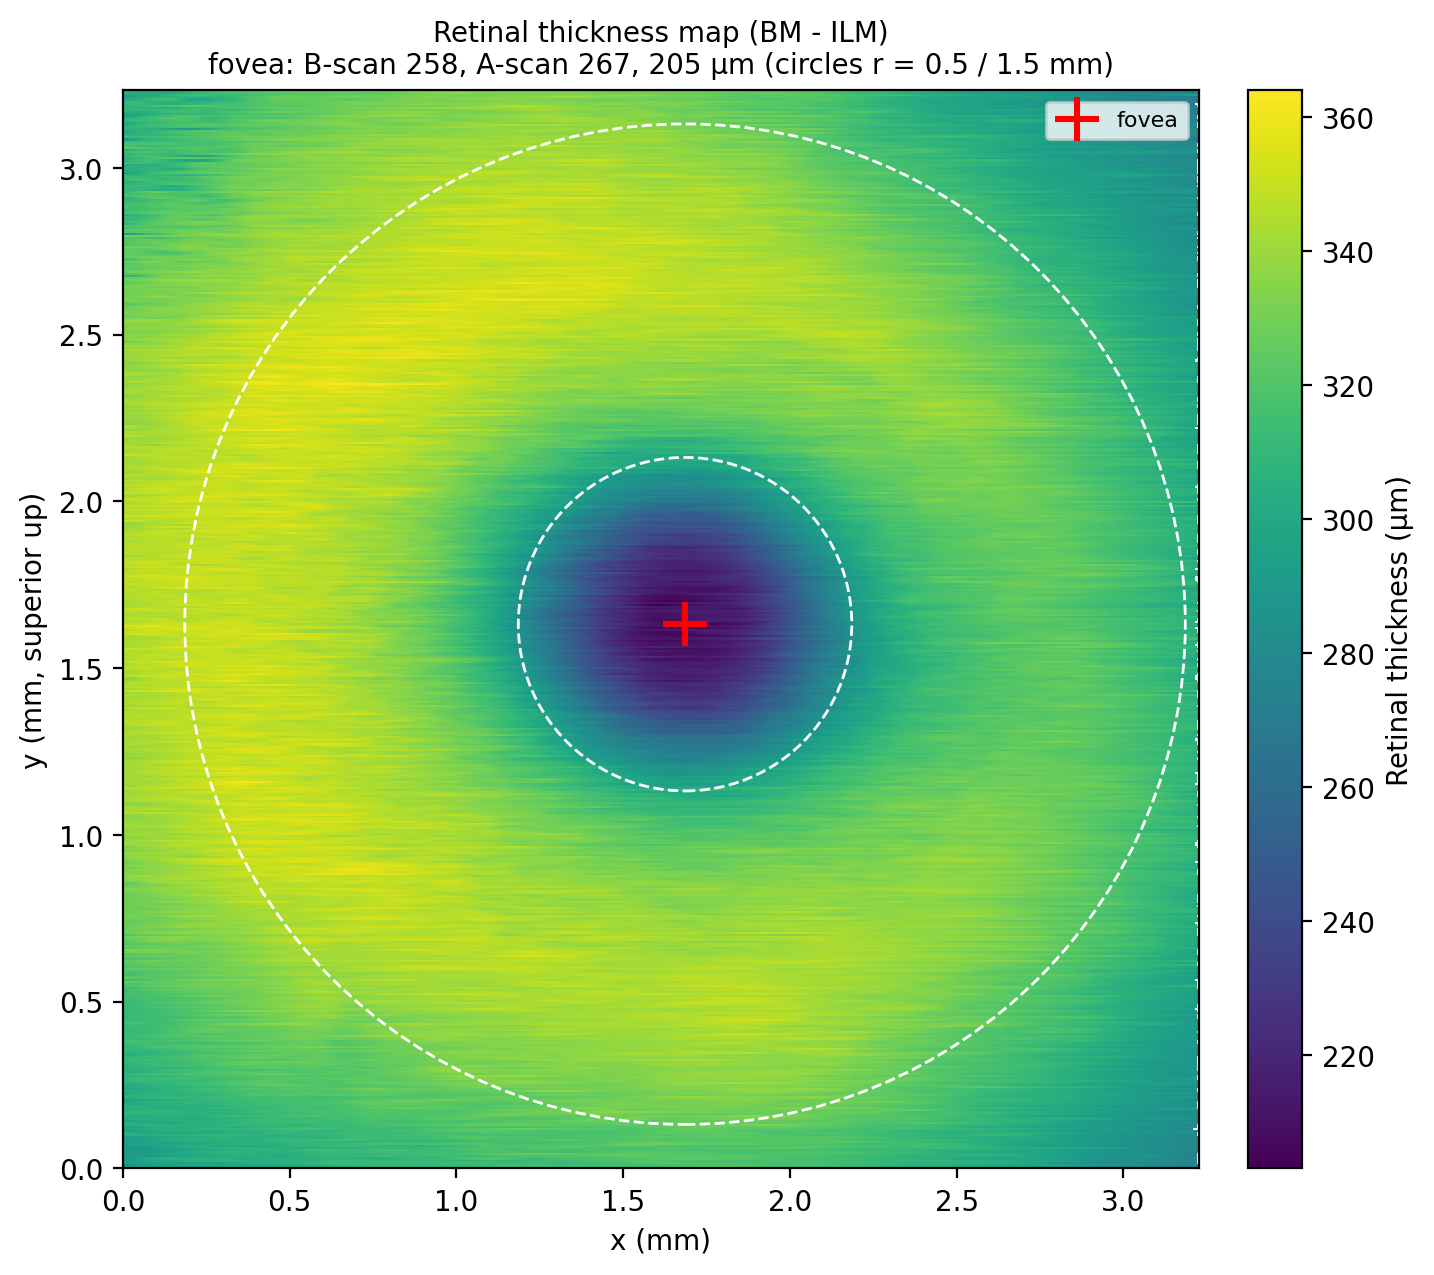


 12_fovea_bscan.png


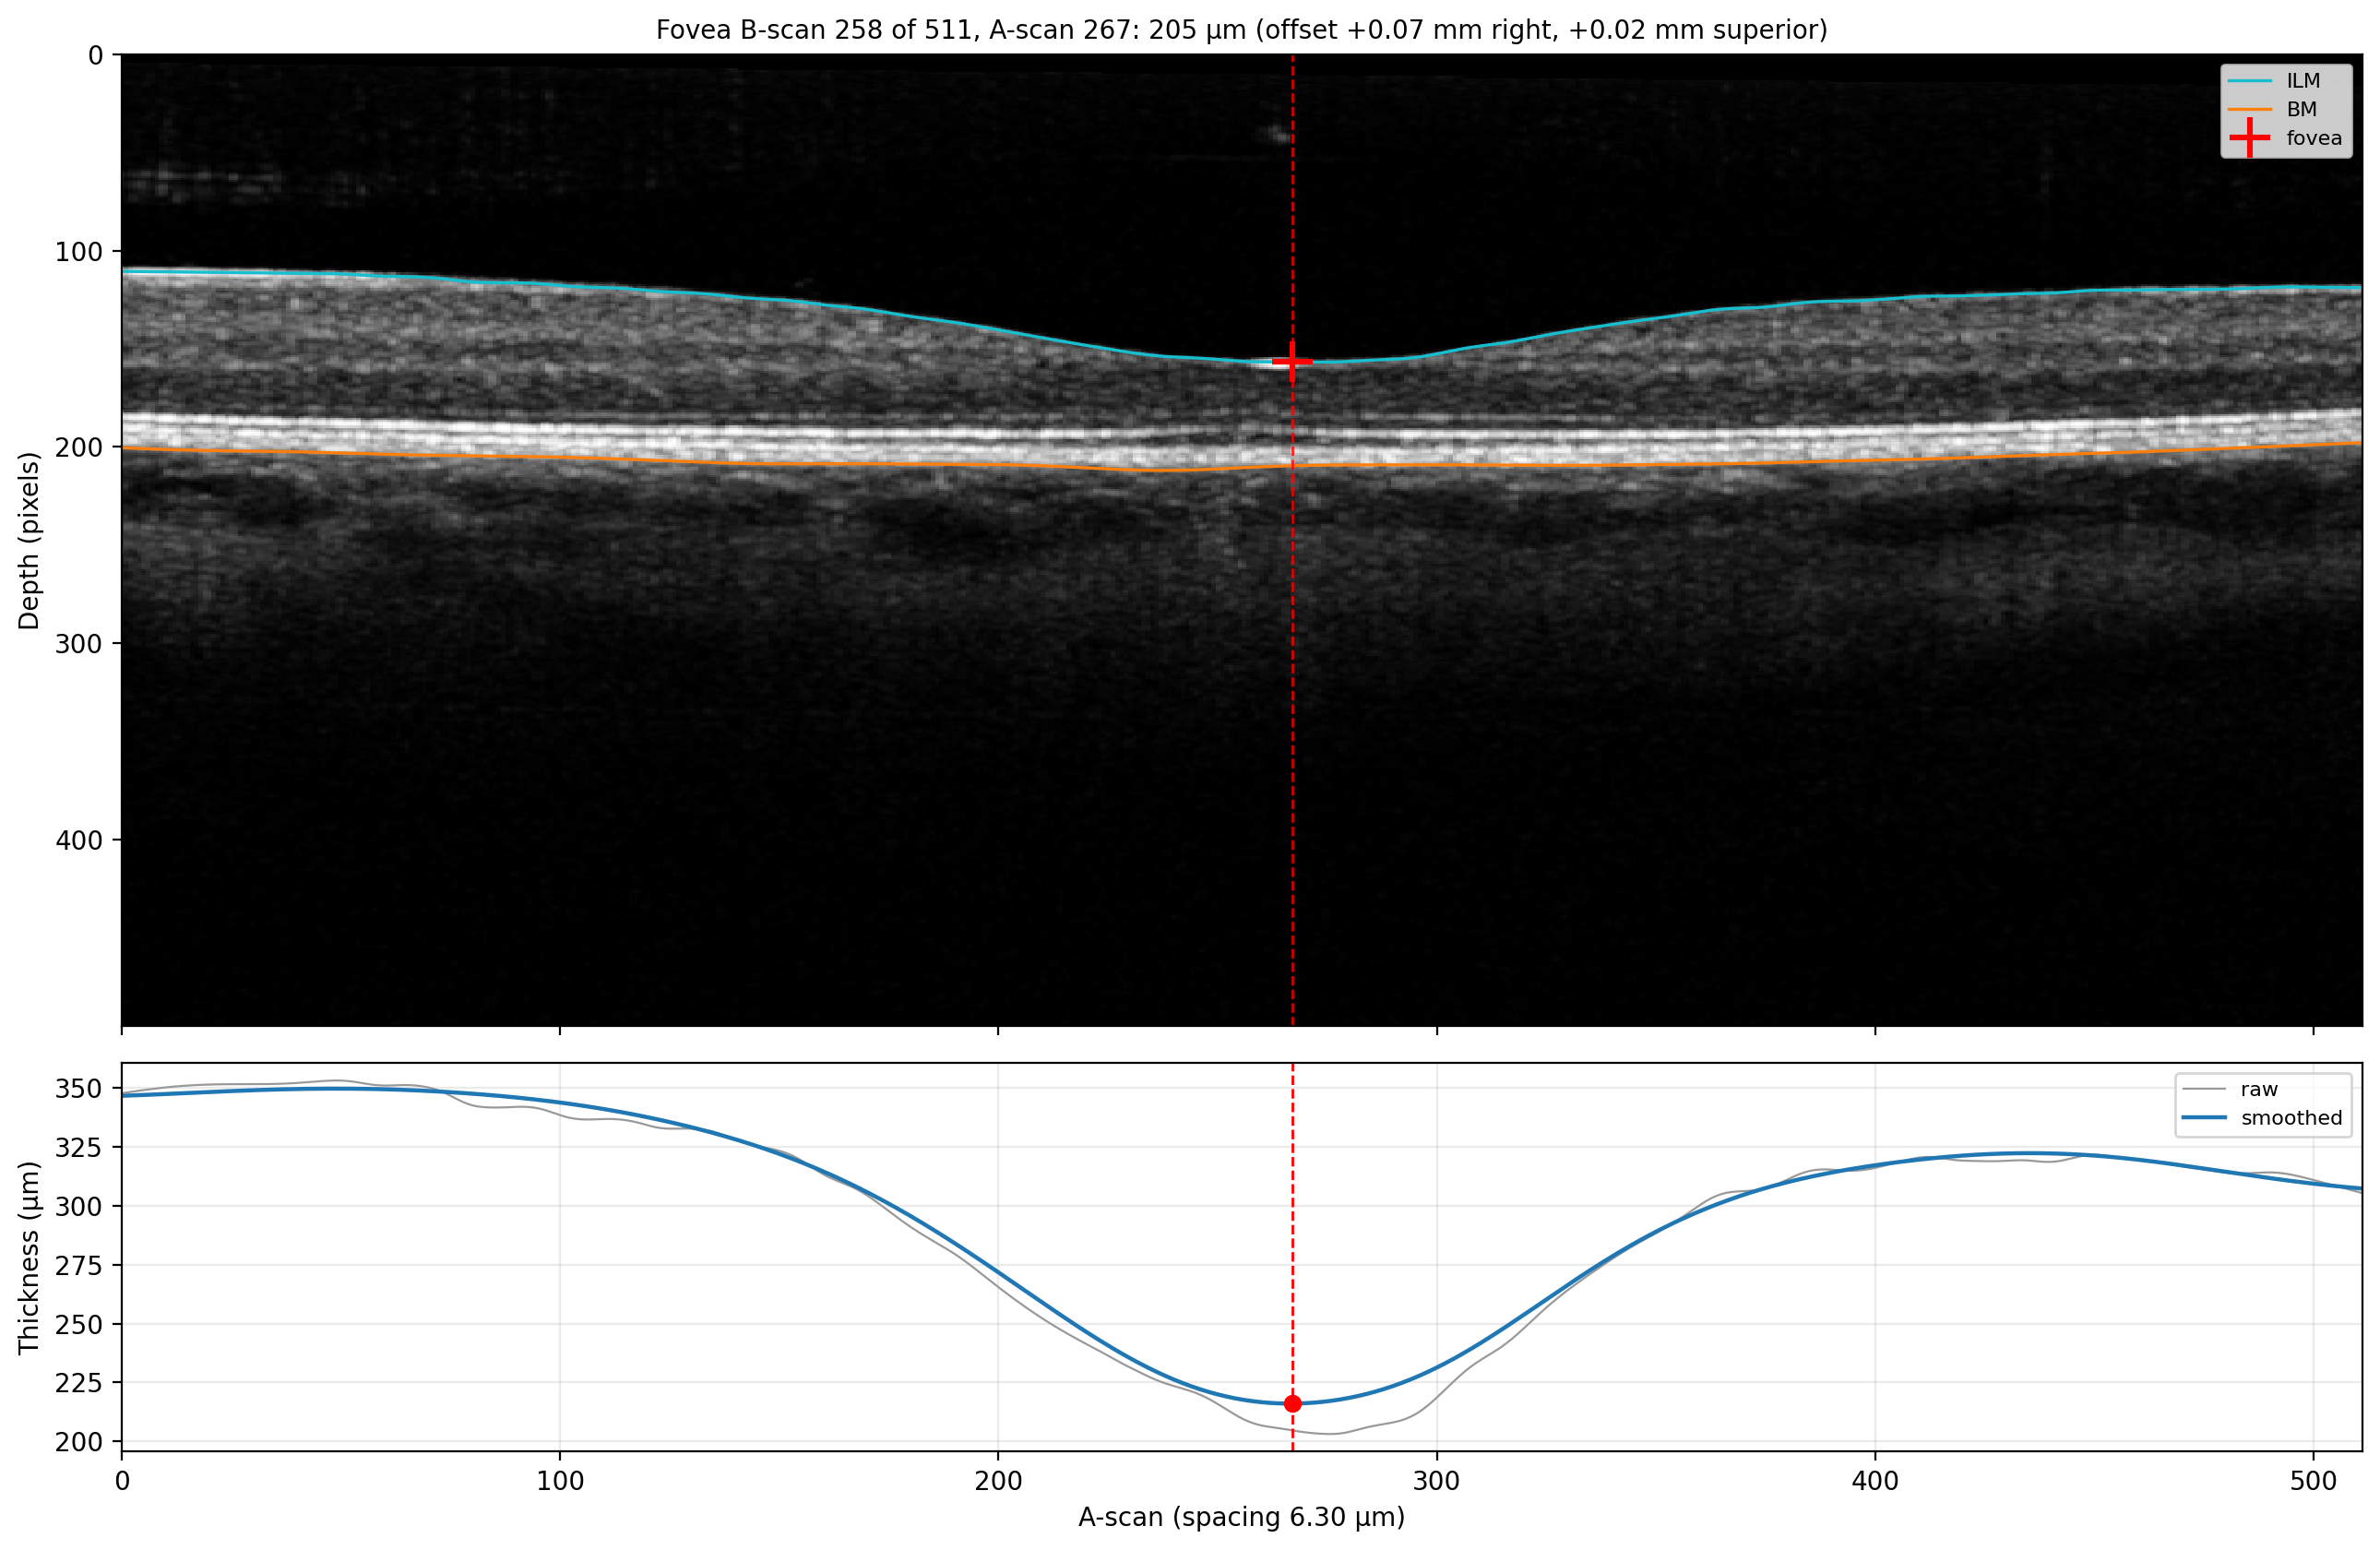


 13_etdrs_retinal_thickness_report.png


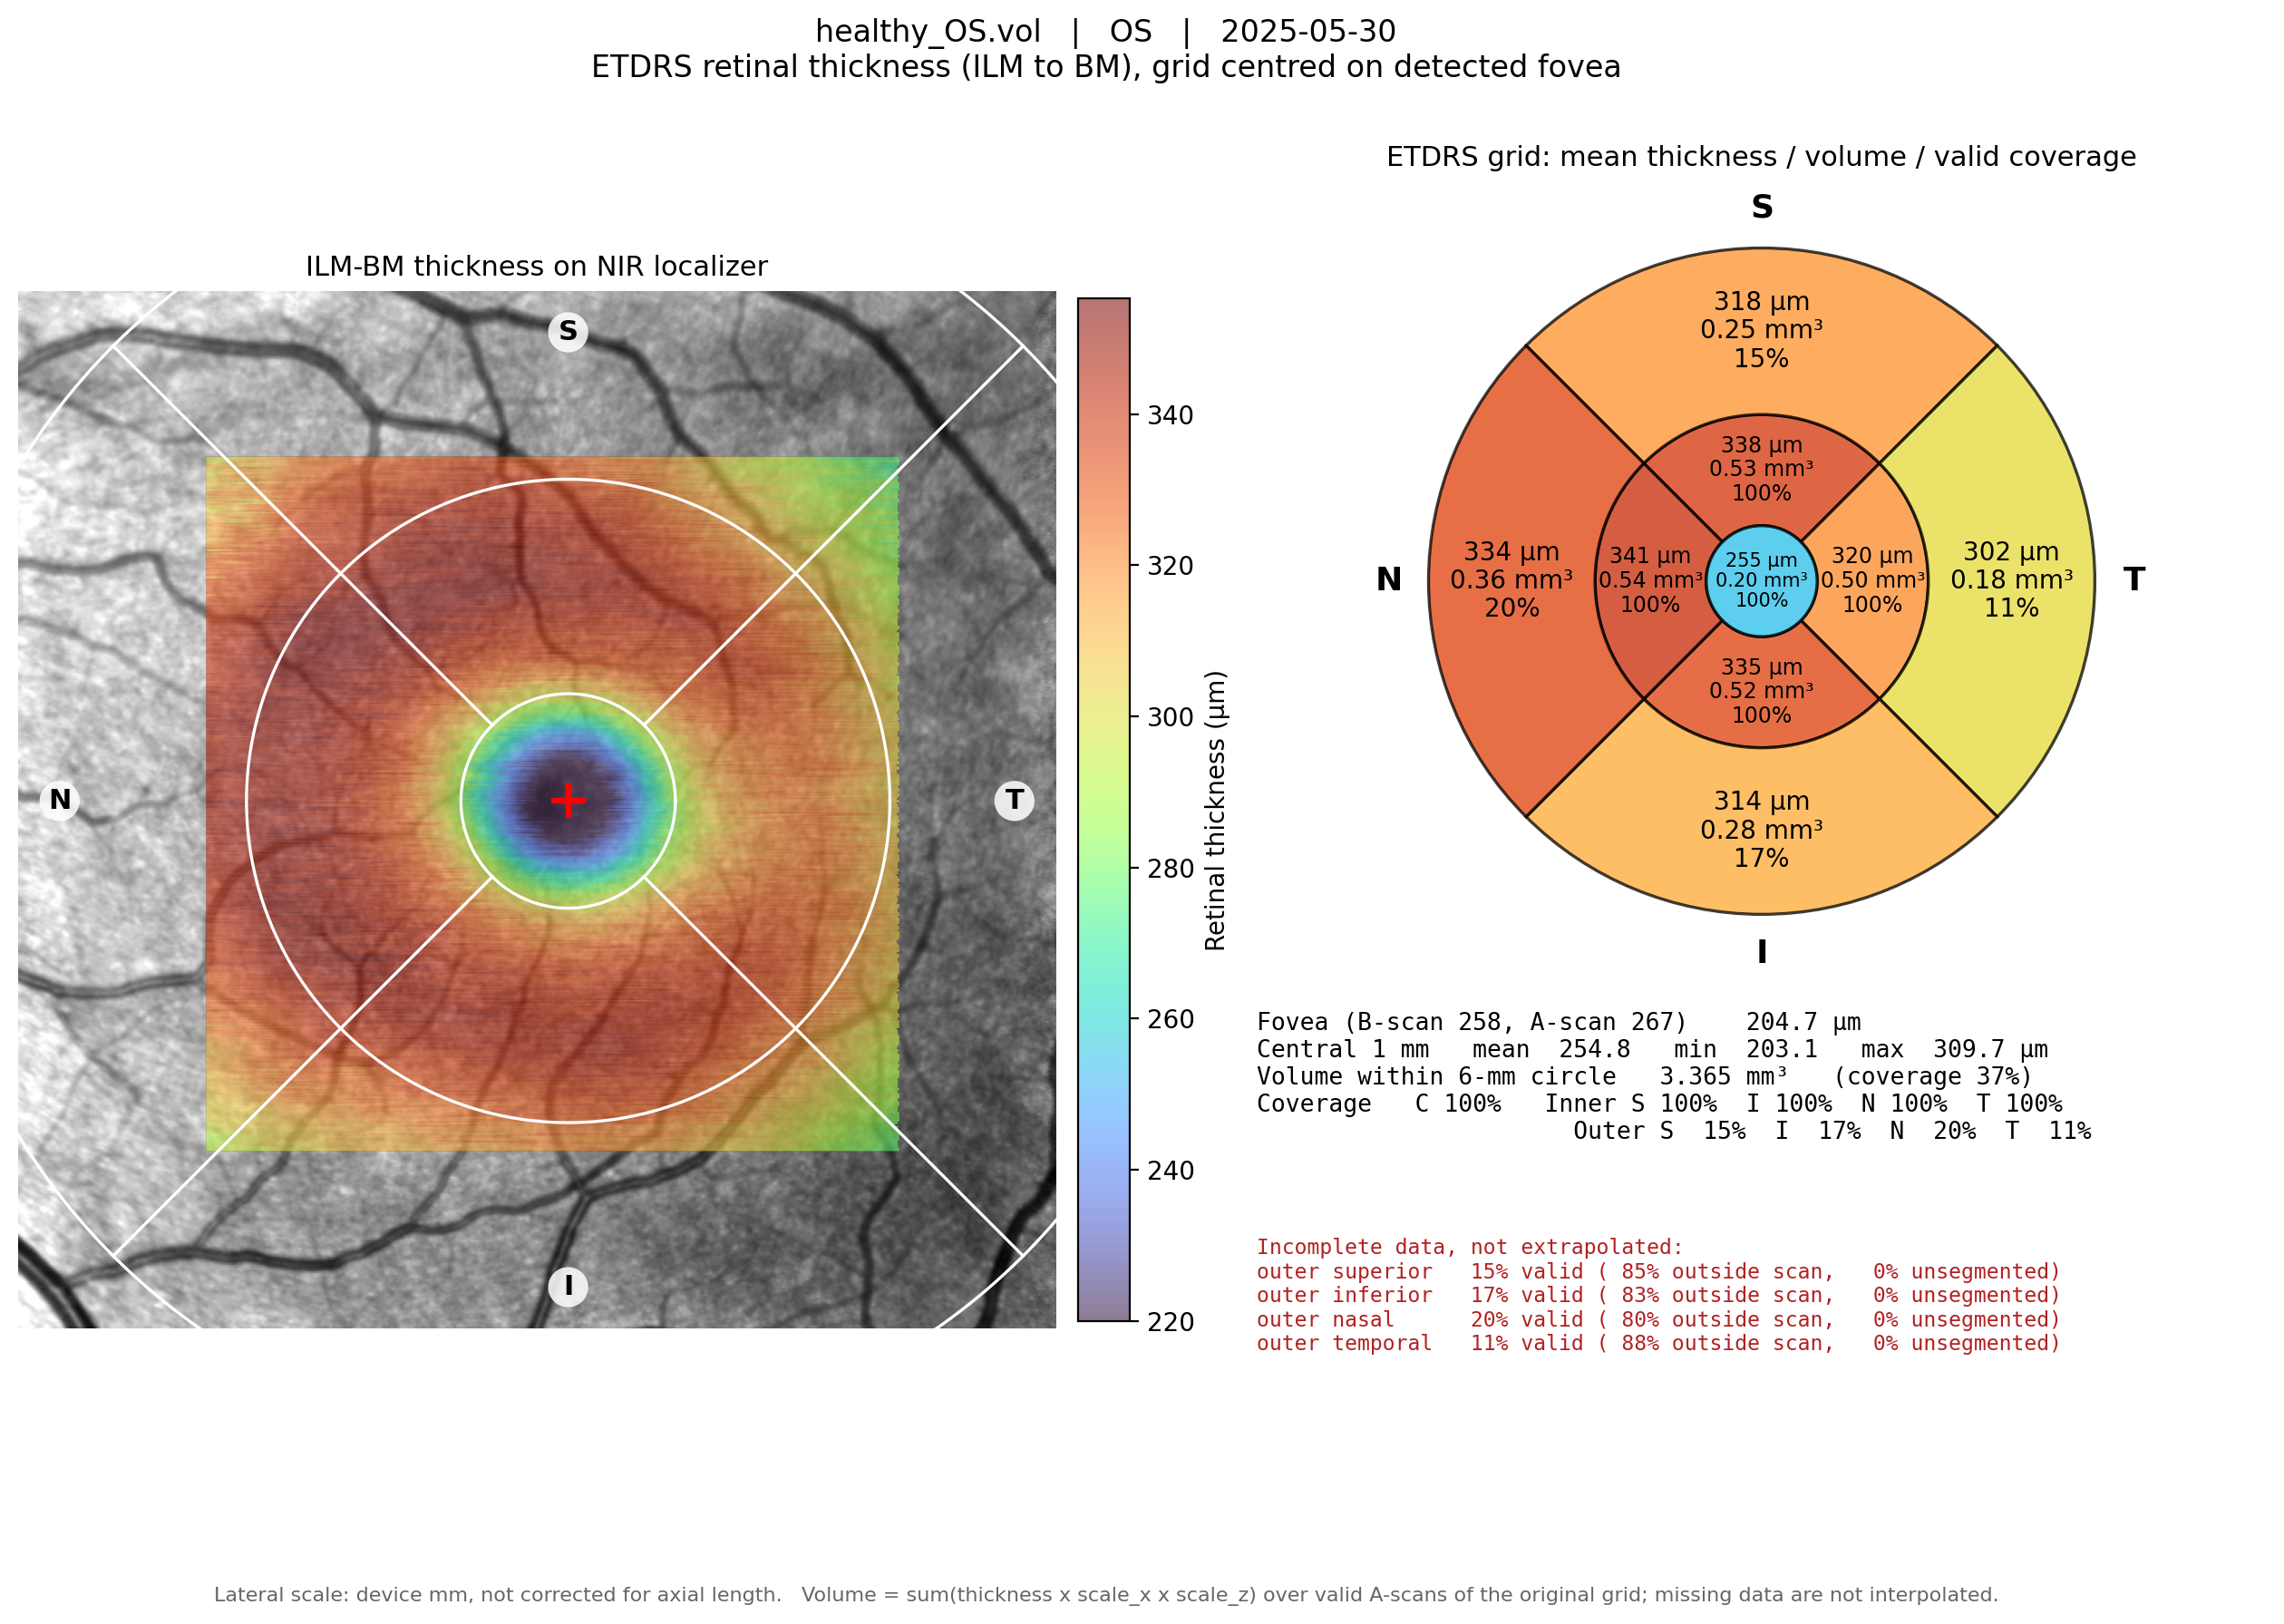


Saved figures: 554
Output folder: /content/vol_samples/vol_outputs


In [6]:
import pandas as pd
from pathlib import Path
from IPython.display import display, Image

OUT = Path("/content/vol_samples/vol_outputs")
summary = pd.read_csv(OUT / "batch_summary.csv")
display(summary.T)
if not summary["status"].eq("ok").all():
    print("WARNING: At least one volume did not complete successfully.")
    print(summary[["file", "status", "error"]].to_string(index=False))

plot_dir = OUT / "healthy_OS" / "plots"
for stem in (
    "06_retinal_thickness_map",
    "12_fovea_bscan",
    "13_etdrs_retinal_thickness_report",
):
    path = plot_dir / (stem + ".png")
    if path.exists():
        print("\n", path.name)
        display(Image(filename=str(path), width=900))
    else:
        print("Not generated:", path.name)

print("\nSaved figures:", len(list(OUT.rglob("*.png"))))
print("Output folder:", OUT)

## 5 — Download a ZIP of the results

Run this cell after processing; it compresses the output folder into a ZIP for download to your computer.

In [7]:
from pathlib import Path
from shutil import make_archive
from google.colab import files

root = Path("/content/vol_samples/vol_outputs")
assert (root / "batch_summary.csv").exists(), "Please run the analysis first"
archive = make_archive("/content/spectralis_healthy_OS_results", "zip", root_dir=root)
print("Created:", archive)
files.download(archive)

Created: /content/spectralis_healthy_OS_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes

- **No private research data:** The notebook downloads a publicly released sample only; your private Google Drive is never mounted.
- **Temporary storage:** Colab runtime resets erase the `.vol` and generated results unless you download/save them.
- **Large sample:** The public OCT volume is about 517 MiB; a free CPU runtime should ordinarily be sufficient, but processing time and memory depend on the runtime.
- **Source attribution:** Sample data released by [MedVisBonn/eyepydata](https://github.com/MedVisBonn/eyepydata/releases/tag/v1.0.0); verify data redistribution requirements before publishing derived outputs.